In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from itertools import cycle
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision.transforms as transforms
from torchvision import models
from torchvision.datasets import ImageFolder
from felaswin_net import FeLASwinNet
import Training_Evaluation_Fuctions  
from Training_Evaluation_Fuctions import (
    train_model,
    evaluate_model,
    evaluate_model_with_metrics,
    run_corruption_analysis,
    run_uncertainty_analysis,
)
# ignore the warnings 
import warnings
warnings.filterwarnings('ignore')

# Dataset Loading

In [4]:
data_dir = "D:\\archive_4\\preprocessed"

In [5]:
# Custom dataset loader for image data
class CustomImageDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform
    
    def __len__(self):
        return len(self.filepaths)
    
    def __getitem__(self, idx):
        image = cv2.imread(self.filepaths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Load data

def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            
            filepaths.append(fpath)
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

# data_dir = "F:\\Ml files\\XAI\\Grape\\Combined (D4)"
df = loading_the_data(data_dir)

       Class  Number of Images
0    COVID19              4192
1     NORMAL              1583
2  PNEUMONIA              4273


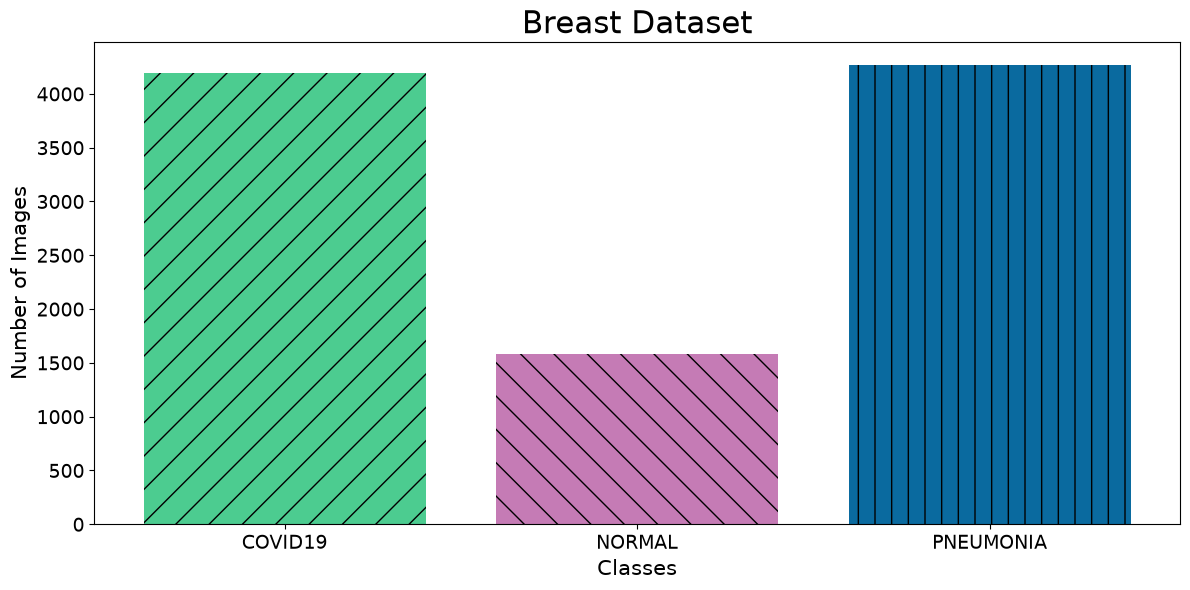

In [6]:
import random
plt.style.use('default')

# Get the list of categories (subfolder names)
categories = [folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))]

# Count the number of images in each category
image_counts = []
for category in categories:
    category_path = os.path.join(data_dir, category)
    image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]
    image_counts.append(len(image_files))

# Create a dataframe to show the number of images per class
data = pd.DataFrame({"Class": categories, "Number of Images": image_counts})
print(data)


# Create a bar chart to visualize the number of images in each category
plt.figure(figsize=(12, 6))
patterns = ["/", "\\", "|", "-", "+", "x", "o", "*"]  # Define patterns for bars
colors = ["#" + ''.join(random.choices('0123456789ABCDEF', k=6)) for _ in categories]  # Generate unique colors
bars = plt.bar(categories, image_counts, color=colors)
for bar, pattern in zip(bars, patterns):
    bar.set_hatch(pattern)

plt.title("Breast Dataset", fontsize=22)
plt.xlabel("Classes", fontsize=15)
plt.ylabel("Number of Images", fontsize=15)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig('D:\\CapstoneProjectModel\\KidneyDist.png', format='png', dpi=600)
plt.show()


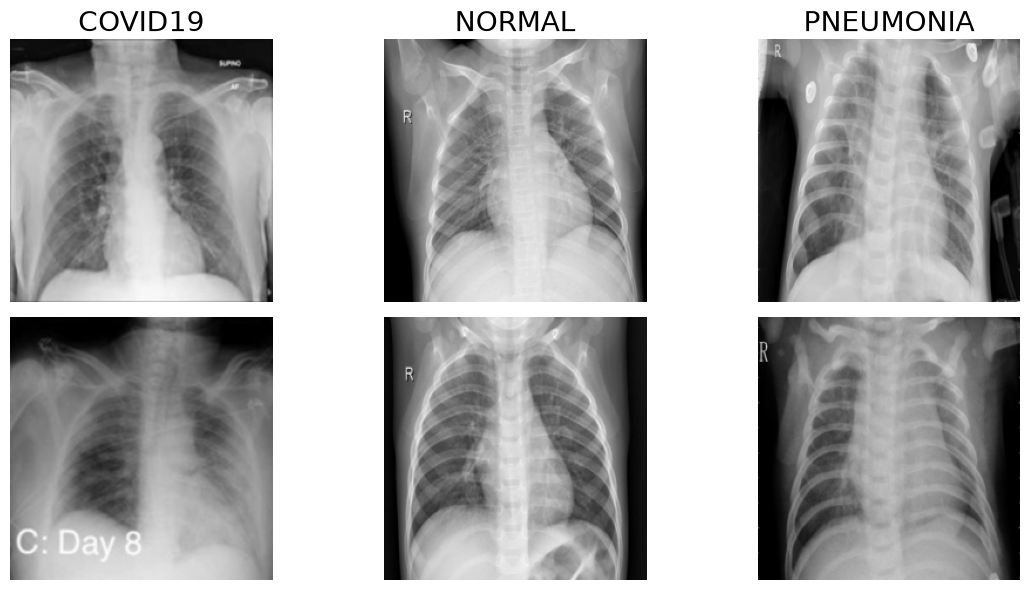

In [18]:
from PIL import Image

# Define a transform to resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 512x512 for uniformity
    transforms.ToTensor()
])

# Number of rows and columns
rows, cols = 2, 3

# Ensure categories list contains at least `cols` categories
if len(categories) < cols:
    raise ValueError("Not enough categories to display.")

# Initialize a figure for visualization
plt.figure(figsize=(12, 6))  # Adjusted figure size for better clarity with 2 rows and 5 columns

# Iterate twice to create two rows with different images from the same categories
for row in range(rows):
    for col, category in enumerate(categories[:cols]):  # Use the first `cols` categories
        # Get the path of the category folder
        category_path = os.path.join(data_dir, category)

        # Get the list of image files in the category folder
        image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]

        # Ensure there is at least one image in the category
        if not image_files:
            print(f"No images found in category: {category}")
            continue

        # Randomly select an image from the category
        image_path = os.path.join(category_path, random.choice(image_files))
        image = Image.open(image_path).convert("RGB")

        # Apply the transform
        image = transform(image)

        # Convert the tensor back to a PIL image for visualization
        image = transforms.ToPILImage()(image)

        # Add the image to the plot
        plt.subplot(rows, cols, row * cols + col + 1)
        plt.imshow(image)
        
        # Set title only for the first row
        if row == 0:
            plt.title(category, fontsize=20)
        
        plt.axis('off')

# Adjust layout and display the plot
plt.tight_layout()
plt.savefig('D:\\CapstoneProjectModel\\PneumoSample.png', format='png', dpi=600)
plt.show()

# Data Preprocessing 

In [23]:
from PIL import Image

INPUT_FOLDER = r'D:\archive_4\Original'
OUTPUT_FOLDER = r'D:\archive_4\preprocessed1'
RESIZE_DIM = 512

# Autocrop params
BORDER_INTENSITY_THRESH = 0.02


def load_grayscale(path: str) -> np.ndarray:
    """Load any supported format (including .npy) as a single-channel uint8 array."""
    if path.lower().endswith('.npy'):
        data = np.load(path)
        if data.ndim == 3:
            data = data[data.shape[0] // 2]
        arr = data.astype(np.float32)
    else:
        img = Image.open(path).convert('L')
        arr = np.array(img, dtype=np.float32)

    # Normalize to 0-255 uint8 regardless of source bit depth
    arr -= arr.min()
    if arr.max() > 0:
        arr = arr / arr.max() * 255.0
    return arr.astype(np.uint8)


def autocrop_content(gray: np.ndarray) -> np.ndarray:
    """
    Tight content-aware crop: finds bounding box of anatomy by thresholding
    out near-black background/borders without extra margin padding.
    """
    h, w = gray.shape
    thresh_val = BORDER_INTENSITY_THRESH * 255

    _, mask = cv2.threshold(gray, thresh_val, 255, cv2.THRESH_BINARY)

    # Clean up small specks (artifacts, scanner noise at edges)
    kernel = np.ones((15, 15), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    coords = cv2.findNonZero(mask)
    if coords is None:
        return gray

    x, y, cw, ch = cv2.boundingRect(coords)

    # Sanity check: reject absurd crops
    if cw < 0.3 * w or ch < 0.3 * h:
        return gray

    # Return tight crop with zero padding
    return gray[y:y + ch, x:x + cw]

def direct_resize(gray: np.ndarray, target: int = RESIZE_DIM) -> np.ndarray:
    """Directly resizes image to target dimensions without canvas zero-padding."""
    return cv2.resize(gray, (target, target), interpolation=cv2.INTER_LANCZOS4)



def process_image(input_path: str) -> np.ndarray:
    gray = load_grayscale(input_path)
    gray = autocrop_content(gray)
    gray = direct_resize(gray, RESIZE_DIM)
    return gray


def main():
    for root, _, files in os.walk(INPUT_FOLDER):
        rel_path = os.path.relpath(root, INPUT_FOLDER)
        target_dir = os.path.join(OUTPUT_FOLDER, rel_path)
        os.makedirs(target_dir, exist_ok=True)

        for filename in files:
            if not filename.lower().endswith(('.bmp', '.jpg', '.jpeg', '.png', '.tif', '.npy')):
                continue

            input_path = os.path.join(root, filename)
            base_name = os.path.splitext(filename)[0]
            output_path = os.path.join(target_dir, f"{base_name}.jpg")

            try:
                processed_rgb = process_image(input_path)
                out_img = Image.fromarray(processed_rgb)
                out_img.save(output_path, format='JPEG', quality=100)
                print(f"Processed: {os.path.join(rel_path, filename)} -> {output_path}")
            except Exception as e:
                print(f"Error processing {filename}: {e}")

    print(f"\nDone. Outputs saved to {OUTPUT_FOLDER}")


if __name__ == "__main__":
    main()

Processed: COVID19\COVID-1.png -> D:\archive_4\preprocessed1\COVID19\COVID-1.jpg
Processed: COVID19\COVID-10.png -> D:\archive_4\preprocessed1\COVID19\COVID-10.jpg
Processed: COVID19\COVID-100.png -> D:\archive_4\preprocessed1\COVID19\COVID-100.jpg
Processed: COVID19\COVID-1000.png -> D:\archive_4\preprocessed1\COVID19\COVID-1000.jpg
Processed: COVID19\COVID-1001.png -> D:\archive_4\preprocessed1\COVID19\COVID-1001.jpg
Processed: COVID19\COVID-1002.png -> D:\archive_4\preprocessed1\COVID19\COVID-1002.jpg
Processed: COVID19\COVID-1003.png -> D:\archive_4\preprocessed1\COVID19\COVID-1003.jpg
Processed: COVID19\COVID-1004.png -> D:\archive_4\preprocessed1\COVID19\COVID-1004.jpg
Processed: COVID19\COVID-1005.png -> D:\archive_4\preprocessed1\COVID19\COVID-1005.jpg
Processed: COVID19\COVID-1006.png -> D:\archive_4\preprocessed1\COVID19\COVID-1006.jpg
Processed: COVID19\COVID-1007.png -> D:\archive_4\preprocessed1\COVID19\COVID-1007.jpg
Processed: COVID19\COVID-1008.png -> D:\archive_4\prepr

#  Data Transformation & Splitting

In [7]:
data_transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to Tensor first
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['labels'], random_state=42)  # 80% train, 20% temp
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['labels'], random_state=42)  # 75% of temp (15% of total) for test


In [9]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)


           Training  Validation  Testing  Total
labels                                         
PNEUMONIA      3418         428      427   4273
COVID19        3354         419      419   4192
NORMAL         1266         158      159   1583


# Train set Augmentation

In [10]:
from PIL import Image
import albumentations as A

# --------------------------------------------------
# AUGMENTATION PIPELINE
# Albumentations replacement for the imgaug pipeline
# --------------------------------------------------
train_aug = A.Compose([
    # 1. Spatial Transforms (Mimics patient misalignment & breathing)
    A.ShiftScaleRotate(
        shift_limit=0.1,   # Minor centering shifts
        scale_limit=0.1,   # Minor distance variations
        rotate_limit=15,     # Restrict rotation to 15 degrees max
        border_mode=cv2.BORDER_CONSTANT, 
        value=0, 
        p=0.5
    ),
    A.ElasticTransform(
        alpha=300, 
        sigma=10, 
        alpha_affine=0, 
        p=0.3
    ), # Simulates varying lung capacities
    
    # 2. Pixel-level Transforms (Mimics machine exposure & noise)
    A.RandomBrightnessContrast(
        brightness_limit=0.1, 
        contrast_limit=0.1, 
        p=0.5
    ),
    A.GaussNoise(
        var_limit=(5.0, 15.0), 
        p=0.3
    ),
])

# --------------------------------------------------
# OFFLINE TRAIN AUGMENTATION FUNCTION
# --------------------------------------------------
def offline_augment_train(train_df, output_root, target_per_class=2000):

    os.makedirs(output_root, exist_ok=True)

    for label in train_df['labels'].unique():

        print(f"\nProcessing class: {label}")

        class_df = train_df[train_df['labels'] == label]
        class_images = class_df['filepaths'].values

        class_output_dir = os.path.join(output_root, label)
        os.makedirs(class_output_dir, exist_ok=True)

        original_count = len(class_images)

        # --------------------------------------------------
        # Copy original images first
        # --------------------------------------------------
        for idx, img_path in enumerate(class_images):

            img = Image.open(img_path).convert("RGB")

            save_path = os.path.join(
                class_output_dir,
                f"original_{idx}.jpg"
            )

            img.save(save_path, quality=100)

        print(f"Original images saved: {original_count}")

        # --------------------------------------------------
        # Determine augmentations needed
        # --------------------------------------------------
        if original_count >= target_per_class:
            print("No augmentation needed (already balanced).")
            continue

        augment_needed = target_per_class - original_count

        augment_per_image = augment_needed // original_count + 1

        augmented_count = 0

        # --------------------------------------------------
        # Generate augmented images
        # --------------------------------------------------
        for idx, img_path in enumerate(tqdm(class_images)):

            image = np.array(
                Image.open(img_path).convert("RGB")
            )

            for j in range(augment_per_image):

                # Albumentations augmentation
                augmented = train_aug(image=image)

                augmented_image = augmented["image"]

                augmented_pil = Image.fromarray(
                    augmented_image
                )

                save_path = os.path.join(
                    class_output_dir,
                    f"aug_{idx}_{j}.jpg"
                )

                augmented_pil.save(
                    save_path,
                    quality=100
                )

                augmented_count += 1

                # Stop exactly at target_per_class
                if original_count + augmented_count >= target_per_class:
                    break

            if original_count + augmented_count >= target_per_class:
                break

        print(f"Augmented images created: {augmented_count}")
        print(
            f"Total images in class '{label}': "
            f"{original_count + augmented_count}"
        )

In [11]:
expanded_train_dir = "D:\\Pneumonia\\TrainAug"

offline_augment_train(
    train_df,
    expanded_train_dir,
    target_per_class=4000   # ← choose desired class size
)


Processing class: COVID19
Original images saved: 3354


 19%|█▉        | 645/3354 [00:05<00:23, 115.20it/s]


Augmented images created: 646
Total images in class 'COVID19': 4000

Processing class: PNEUMONIA
Original images saved: 3418


 17%|█▋        | 581/3418 [00:04<00:23, 121.66it/s]


Augmented images created: 582
Total images in class 'PNEUMONIA': 4000

Processing class: NORMAL
Original images saved: 1266


 72%|███████▏  | 911/1266 [00:20<00:07, 44.48it/s]

Augmented images created: 2734
Total images in class 'NORMAL': 4000




In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import albumentations as A

def visualize_augmentations(image_path, output_path="augmentation_samples1.jpg"):
    image = np.array(Image.open(image_path).convert("RGB"))

    transform_dict = {
        "Original": None,
        "ShiftScaleRotate": A.Compose([
            A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, 
                               border_mode=cv2.BORDER_CONSTANT, p=1.0)
        ]),
        "ElasticTransform": A.Compose([
            A.ElasticTransform(alpha=300, sigma=10, alpha_affine=0, p=1.0)
        ]),
        "RandomBrightnessContrast": A.Compose([
            A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=1.0)
        ]),
        "GaussNoise": A.Compose([
            A.GaussNoise(var_limit=(5.0, 15.0), p=1.0)
        ])
    }

    fig, axes = plt.subplots(1, 5, figsize=(24, 8), dpi=600)
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (title, transform) in zip(axes, transform_dict.items()):
        if transform is None:
            aug_img = image
        else:
            aug_img = transform(image=image)["image"]

        ax.imshow(aug_img)
        ax.set_title(title, fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.savefig(output_path, dpi=600, bbox_inches="tight")
    plt.show()

visualize_augmentations(r"D:\archive_4\preprocessed\PNEUMONIA\person86_virus_159.jpg")

In [12]:
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)

        for file in filelist:
            filepaths.append(os.path.join(foldpath, file))
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

In [13]:
expanded_train_df = loading_the_data(expanded_train_dir)

In [14]:
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}

train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values

In [15]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    expanded_train_df['filepaths'].values,
    expanded_train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [9]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    train_df['filepaths'].values,
    train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [10]:
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True, num_workers=4, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=32,
                        shuffle=False, num_workers=4, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32,
                         shuffle=False, num_workers=0, pin_memory=True)

In [16]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = expanded_train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)


           Training  Validation  Testing  Total
labels                                         
COVID19        4000         419      419   4838
NORMAL         4000         158      159   4317
PNEUMONIA      4000         428      427   4855


In [24]:
# Online Augmentation Pipeline
train_transform = transforms.Compose([
    # 1. Downsample 512x512 pre-cropped images to target model input
    transforms.Resize((224, 224)),
    # 2. Subtle Spatial Transformations (Mimics slight patient positioning differences)
    transforms.RandomAffine(
        degrees=[-5, 5], 
        translate=(0.05, 0.05), 
        scale=[0.95, 1.05]
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    # 3. Convert PIL Image to PyTorch Tensor
    transforms.ToTensor(),
    
    transforms.RandomErasing(
        p=0.2,                  # Reduced from 0.5
        scale=(0.01, 0.05),     # Reduced from (0.02, 0.08)
        ratio=(0.3, 3.3), 
        value=0
    ),
    
    # 5. Normalization
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


# Validation & Test transforms (No Resize needed)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


# 2. Extract Labels for mappings
label_mapping = {label: idx for idx, label in enumerate(train_df['labels'].unique())}

# Get numerical labels
train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values


# 3. Create Datasets directly from the ORIGINAL dataframes
from my_dataset1 import CustomImageDataset

# Use train_transform here!
train_dataset = CustomImageDataset(
    filepaths=train_df['filepaths'].values,  # <-- Use original train_df
    labels=train_labels,
    transform=train_transform                # <-- Pass the augmentation transform
)

# Use val_test_transform here!
val_dataset = CustomImageDataset(
    filepaths=val_df['filepaths'].values,
    labels=val_labels,
    transform=val_test_transform             # <-- No augmentations
)

# Use val_test_transform here!
test_dataset = CustomImageDataset(
    filepaths=test_df['filepaths'].values,
    labels=test_labels,
    transform=val_test_transform             # <-- No augmentations
)


# 4. Create DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0, 
    pin_memory=True
)

In [25]:
# Model setup
if not torch.cuda.is_available():
    raise RuntimeError('CUDA device is not available. Please ensure a GPU is available to train the model.')
device = torch.device('cuda')

# Proposed Model Initialization and Classification Result

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

# --- 1. Total Epoch & Warmup Config ---
total_epochs = 30
warmup_epochs = 3
# Start averaging once the cosine anneal has mostly flattened out — this is where
# your curves show train still improving while val just adds noise.
num_classes = len(label_mapping)
 
# --- 2. Model & Loss ---
model = FeLASwinNet(
    num_classes=num_classes,
    drop_path_rate=0.05,     # restored — 0.05 wasn't enough to tame the oscillation
    attn_drop_rate=0.01   # restored a small amount rather than 0.0
).to(device)
 
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
 
# --- 3. Parameter Grouping (unchanged — this part was already correct) ---
def get_parameter_groups(model, weight_decay=0.03):
    no_decay = ['bias', 'LayerNorm', 'BatchNorm', 'norm', 'gamma']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0
        }
    ]
    return grouped_parameters
 
# --- 4. AdamW Optimizer — corrected to match the intended 3e-4 ---
optimizer = optim.AdamW(
    get_parameter_groups(model, weight_decay=0.03), 
    lr=5e-4
)
 
warmup_scheduler = LinearLR(
    optimizer, start_factor=0.05, end_factor=1.0, total_iters=warmup_epochs
)
cosine_scheduler = CosineAnnealingLR(
    optimizer, T_max=(total_epochs - warmup_epochs), eta_min=1e-6
)
scheduler = SequentialLR(
    optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs]
)
 

In [24]:
torch.cuda.empty_cache()

In [29]:
model.load_state_dict(torch.load("fetle_swin_hybrid_XRay.pth"))

<All keys matched successfully>


Epoch 1/30
------------------------------


Validation Loss: 0.7456, Validation Accuracy: 0.7778
Training Loss: 0.9867, Training Accuracy: 0.6594

Epoch 2/30
------------------------------


Validation Loss: 0.6420, Validation Accuracy: 0.8450
Training Loss: 0.6573, Training Accuracy: 0.8428

Epoch 3/30
------------------------------


Validation Loss: 0.5305, Validation Accuracy: 0.9186
Training Loss: 0.5717, Training Accuracy: 0.8895

Epoch 4/30
------------------------------


Validation Loss: 0.5014, Validation Accuracy: 0.9257
Training Loss: 0.5379, Training Accuracy: 0.9087

Epoch 5/30
------------------------------


Validation Loss: 0.5197, Validation Accuracy: 0.9109
Training Loss: 0.5118, Training Accuracy: 0.9185
Patience Counter: 1/7

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.3943, Validation Accuracy: 0.9755
Training Loss: 0.3818, Training Accuracy: 0.9847
Patience Counter: 2/7

Epoch 28/30
------------------------------


Validation Loss: 0.3998, Validation Accuracy: 0.9716
Training Loss: 0.3801, Training Accuracy: 0.9864
Patience Counter: 3/7

Epoch 29/30
------------------------------


Validation Loss: 0.3973, Validation Accuracy: 0.9735
Training Loss: 0.3782, Training Accuracy: 0.9873
Patience Counter: 4/7

Epoch 30/30
------------------------------


Validation Loss: 0.3941, Validation Accuracy: 0.9761
Training Loss: 0.3784, Training Accuracy: 0.9869
Patience Counter: 5/7


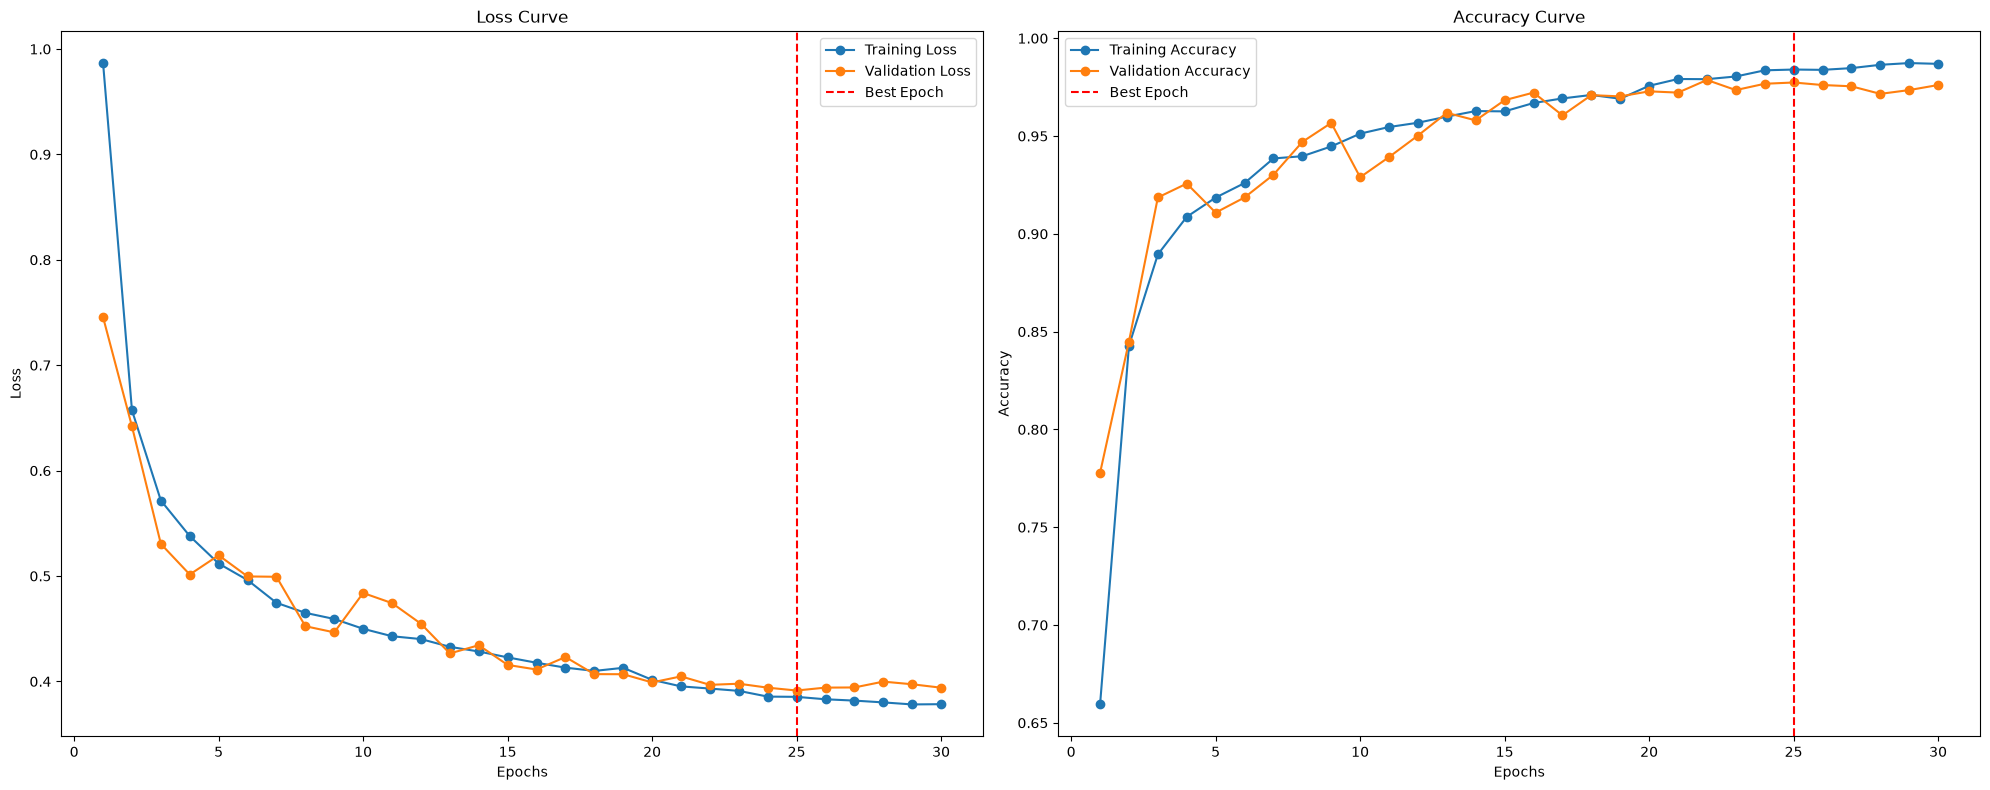


Training Report:
Total training time: 00:17:52
Total epochs run: 30
Best Training Loss: 0.3854 at epoch 25
Best Training Accuracy: 0.9840

Validation Report:
Best Validation Loss: 0.3914 at epoch 25
Best Validation Accuracy: 0.9774
Final Validation Loss: 0.3941
Final Validation Accuracy: 0.9761

Inference Report:
Total Inference Time (Validation only): 00:04:31


In [40]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=7, min_delta=0.001)

In [19]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98905
Recall:      0.98745
Precision:   0.98371
F1 Score:    0.98555
MCC:         0.98240
PR AUC:      0.99758
Kappa:       0.98239
Specificity: 0.99476


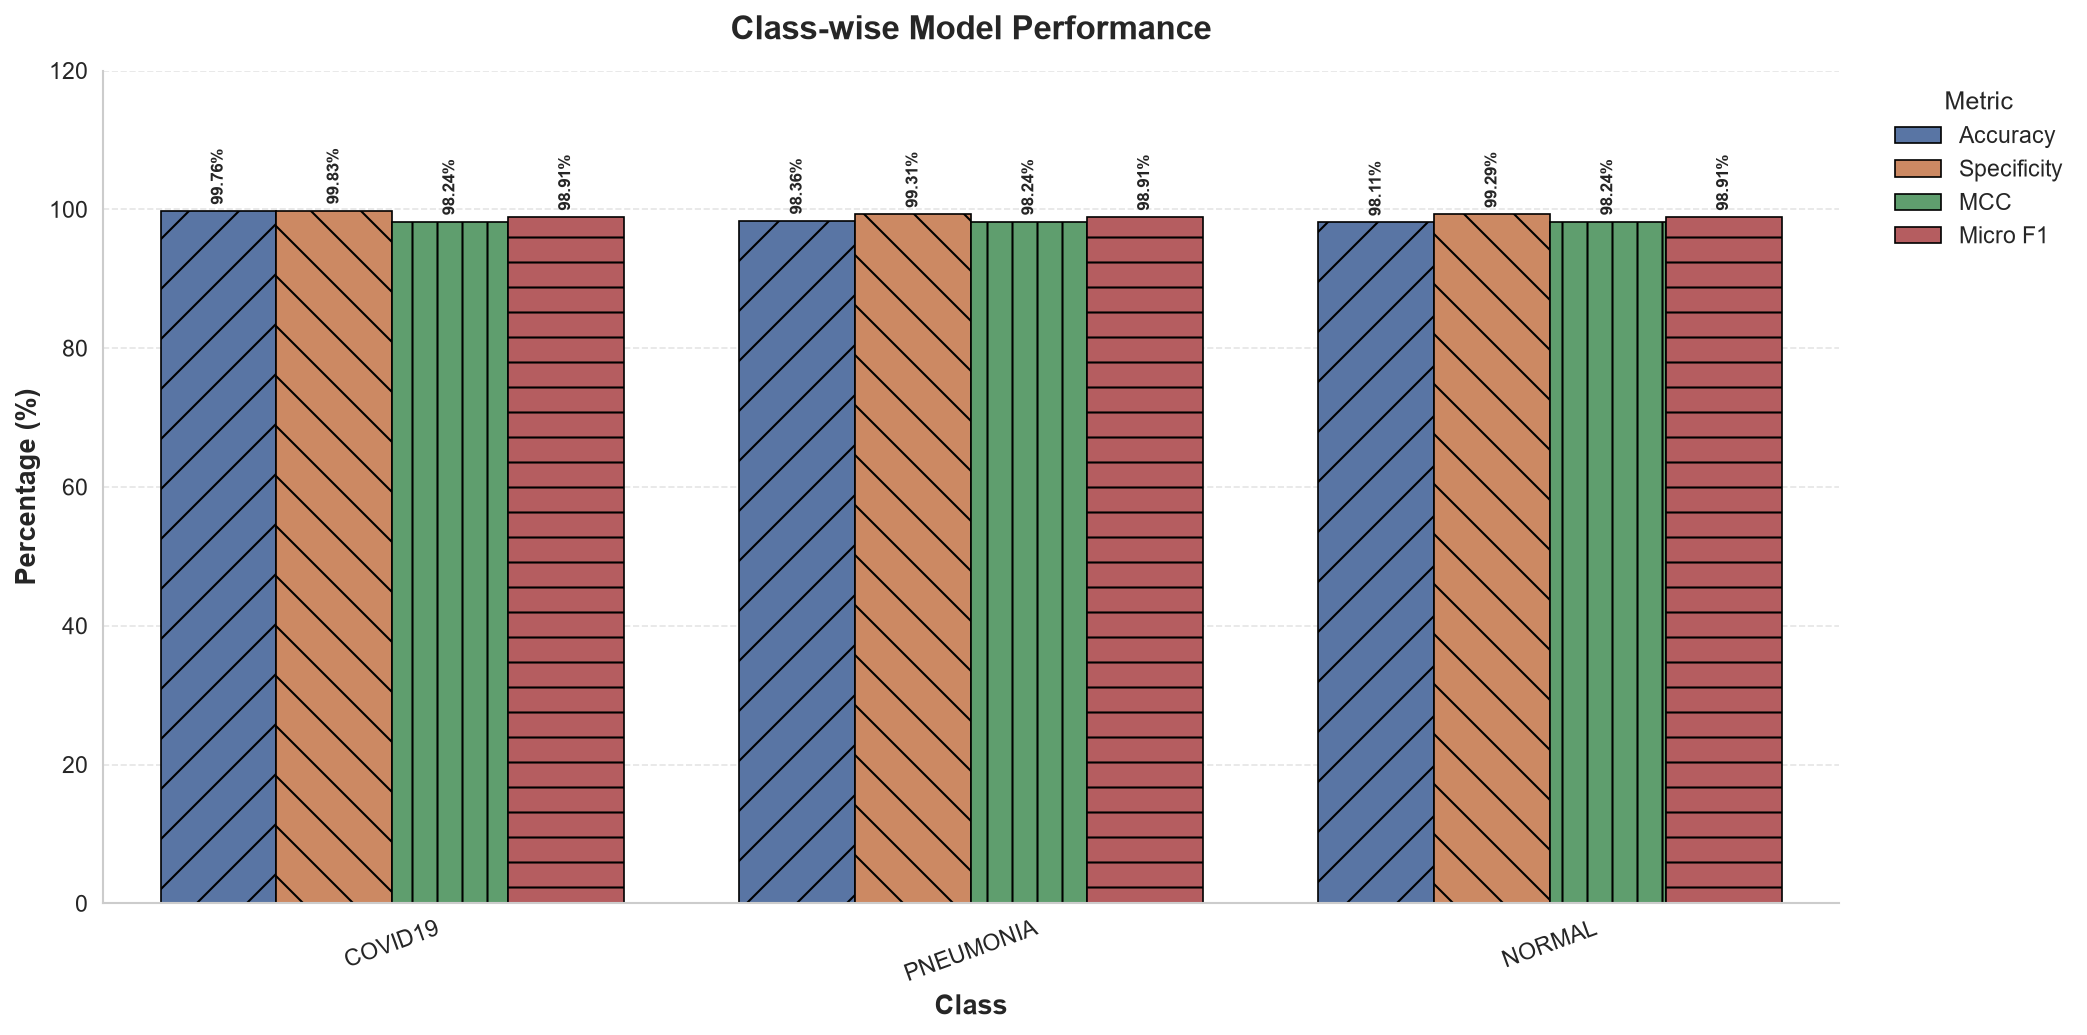

In [20]:
plot_model_performance(model, test_loader, label_mapping=label_mapping, device='cuda', save_path='class_performanceXray.png')


Epoch 1/30
------------------------------


Validation Loss: 0.5513, Validation Accuracy: 0.8378
Training Loss: 0.7302, Training Accuracy: 0.7743

Epoch 2/30
------------------------------


Validation Loss: 0.4282, Validation Accuracy: 0.9453
Training Loss: 0.4735, Training Accuracy: 0.9147

Epoch 3/30
------------------------------


Validation Loss: 0.4056, Validation Accuracy: 0.9423
Training Loss: 0.4167, Training Accuracy: 0.9394

Epoch 4/30
------------------------------


Validation Loss: 0.4085, Validation Accuracy: 0.9363
Training Loss: 0.4026, Training Accuracy: 0.9455
Patience Counter: 1/7

Epoch 5/30
------------------------------


Validation Loss: 0.3722, Validation Accuracy: 0.9582
Training Loss: 0.3896, Training Accuracy: 0.9510

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.3359, Validation Accuracy: 0.9771
Training Loss: 0.3187, Training Accuracy: 0.9879
Patience Counter: 4/7

Epoch 28/30
------------------------------


Validation Loss: 0.3345, Validation Accuracy: 0.9771
Training Loss: 0.3187, Training Accuracy: 0.9874
Patience Counter: 5/7

Epoch 29/30
------------------------------


Validation Loss: 0.3342, Validation Accuracy: 0.9771
Training Loss: 0.3164, Training Accuracy: 0.9879
Patience Counter: 6/7

Epoch 30/30
------------------------------


Validation Loss: 0.3336, Validation Accuracy: 0.9781
Training Loss: 0.3172, Training Accuracy: 0.9884
Patience Counter: 7/7
Early stopping triggered at epoch 30.


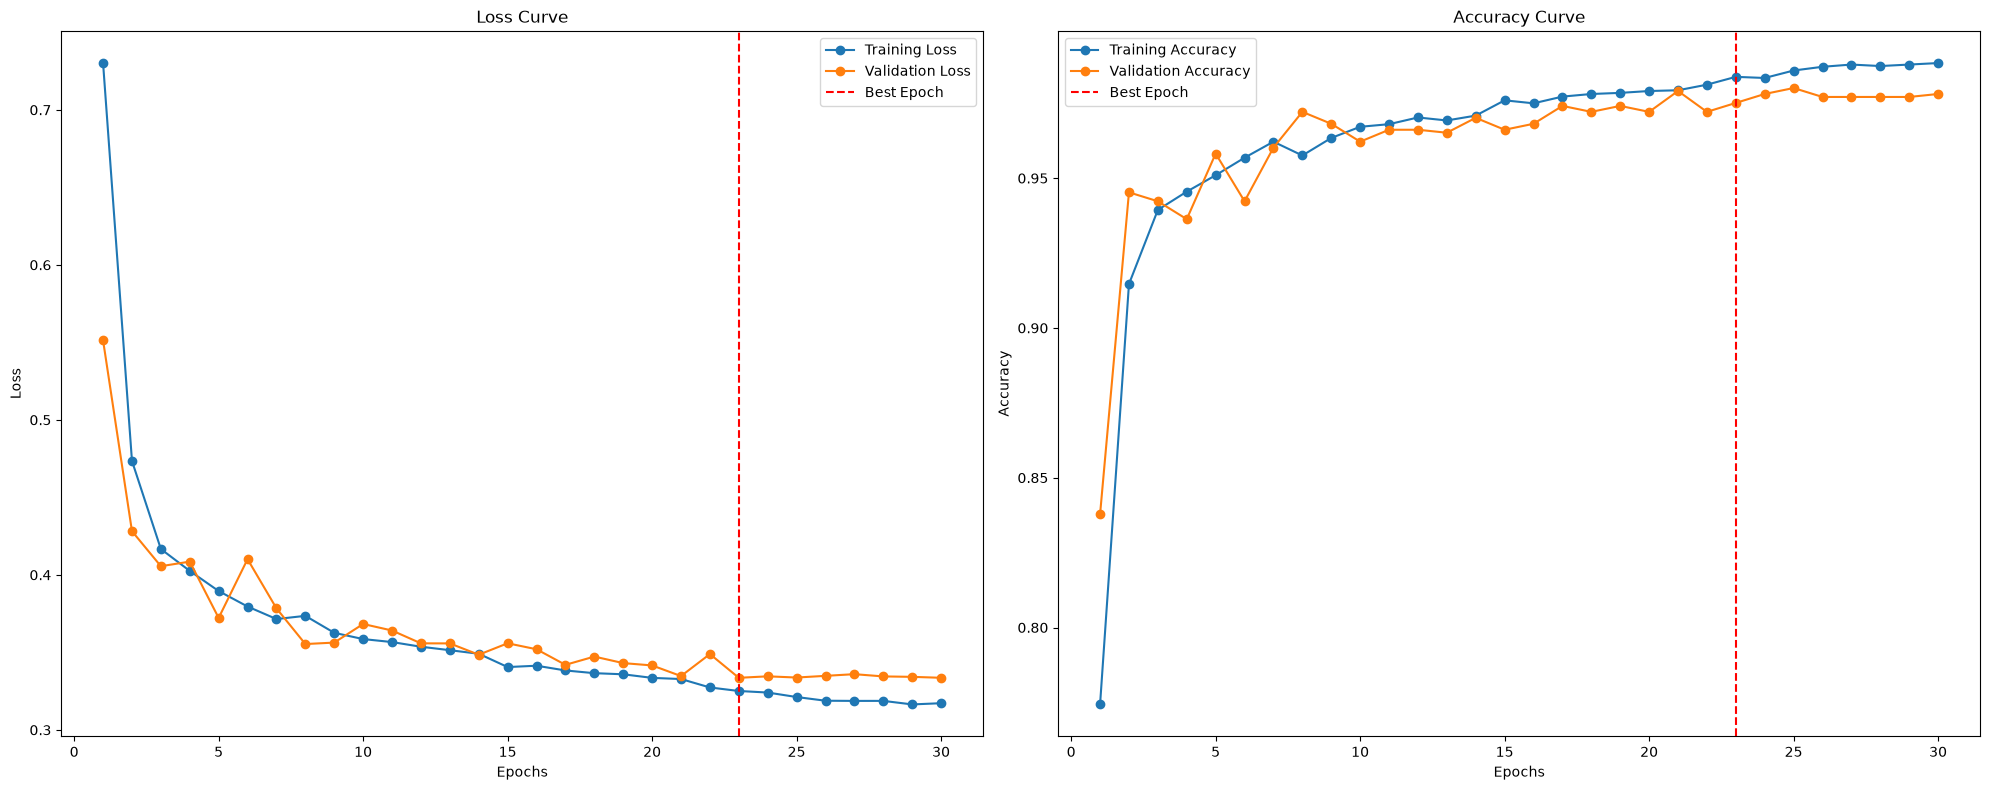


Training Report:
Total training time: 00:12:15
Total epochs run: 30
Best Training Loss: 0.3251 at epoch 23
Best Training Accuracy: 0.9838

Validation Report:
Best Validation Loss: 0.3336 at epoch 23
Best Validation Accuracy: 0.9751
Final Validation Loss: 0.3336
Final Validation Accuracy: 0.9781

Inference Report:
Total Inference Time (Validation only): 00:02:15


In [21]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=7, min_delta=0.001)

Accuracy: 0.9891
              precision    recall  f1-score   support

     COVID19     0.9976    0.9976    0.9976       419
   PNEUMONIA     0.9906    0.9836    0.9871       427
      NORMAL     0.9630    0.9811    0.9720       159

    accuracy                         0.9891      1005
   macro avg     0.9837    0.9875    0.9856      1005
weighted avg     0.9891    0.9891    0.9891      1005



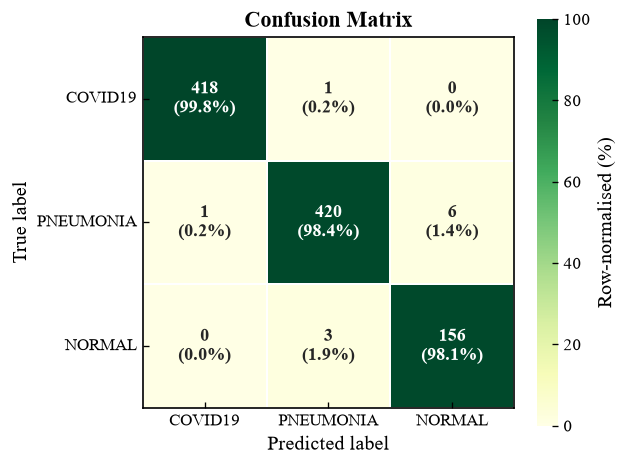

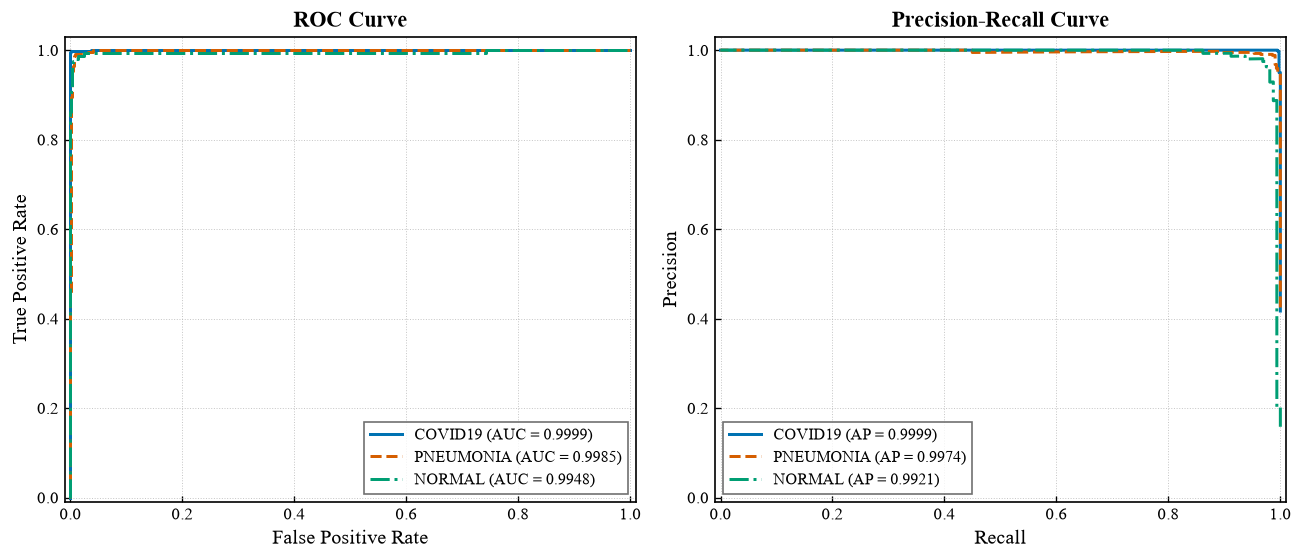

In [30]:
evaluate_model(model, test_loader, label_mapping, device=device, save_dir='figures1', dpi=600)

# Proposed Model's Uncertainty, Robustness and Misprediction Results

CLINICALLY-REALISTIC CORRUPTION ROBUSTNESS
Clean                | Acc=0.9891 | F1=0.9856 | MCC=0.9824
Gaussian Noise       | sev=1 | Acc=0.9891 | F1=0.9861 | MCC=0.9824
Gaussian Noise       | sev=2 | Acc=0.9751 | F1=0.9678 | MCC=0.9599
Gaussian Noise       | sev=3 | Acc=0.7831 | F1=0.7579 | MCC=0.6758
Gaussian Noise       | sev=4 | Acc=0.5114 | F1=0.3682 | MCC=0.2839
Gaussian Blur        | sev=1 | Acc=0.9891 | F1=0.9854 | MCC=0.9824
Gaussian Blur        | sev=2 | Acc=0.9861 | F1=0.9809 | MCC=0.9775
Gaussian Blur        | sev=3 | Acc=0.9811 | F1=0.9734 | MCC=0.9696
Gaussian Blur        | sev=4 | Acc=0.9731 | F1=0.9614 | MCC=0.9570
Brightness Shift     | sev=1 | Acc=0.9672 | F1=0.9548 | MCC=0.9471
Brightness Shift     | sev=2 | Acc=0.9871 | F1=0.9819 | MCC=0.9791
Brightness Shift     | sev=3 | Acc=0.9751 | F1=0.9676 | MCC=0.9601
Brightness Shift     | sev=4 | Acc=0.9502 | F1=0.9418 | MCC=0.9203
JPEG Compression     | sev=1 | Acc=0.9881 | F1=0.9840 | MCC=0.9808
JPEG Compression     | sev=

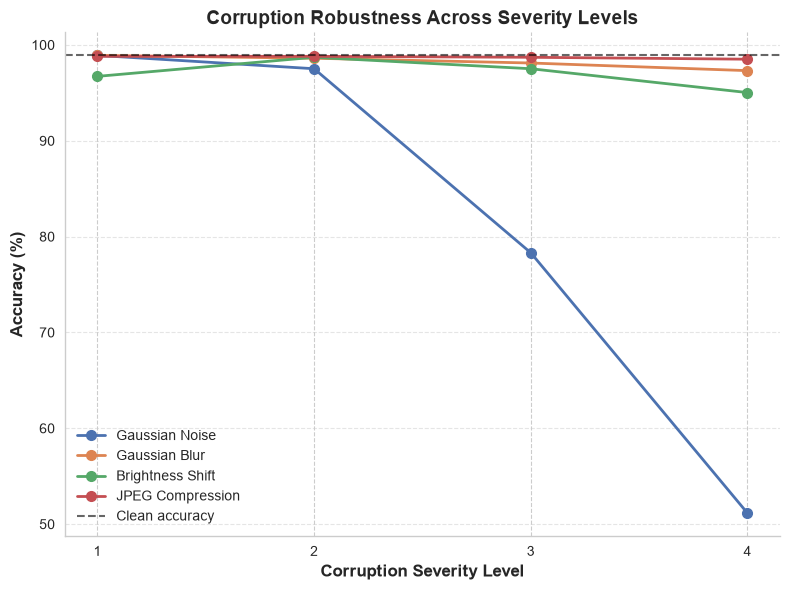

Saved figure: FetleSwinHybrid_corruption2_figure.png / .pdf


In [31]:
# ============================================================
# USAGE
# ============================================================
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # match your data_transform exactly

summary_df, per_severity_df = run_corruption_analysis(
     model=model,
     dataset=test_dataset,     # your CustomImageDataset instance
     device=device,
     mean=mean, std=std,
     save_prefix='FetleSwinHybrid_corruption2'
)

MC DROPOUT UNCERTAINTY ANALYSIS
[Diagnostic] Mean per-sample MC-pass disagreement rate: 0.12%
[Diagnostic] Samples with ANY disagreement across 30 passes: 0.80%
Accuracy: 0.98806 | Macro F1: 0.98409
ECE: 0.06567 | MCE: 0.48105 | Brier: 0.02541 | NLL: 0.09920
Mean predictive entropy: 0.30759 | Aleatoric: 0.30589 | Epistemic: 0.00170

TTA UNCERTAINTY ANALYSIS
Accuracy: 0.98607 | Macro F1: 0.98101
ECE: 0.08937 | MCE: 0.36834 | Brier: 0.03852 | NLL: 0.12640
Mean predictive entropy: 0.35990 | Aleatoric: 0.30942 | Epistemic: 0.05048

Saved: FetleSwinHybrid_uncertainty2_summary.csv


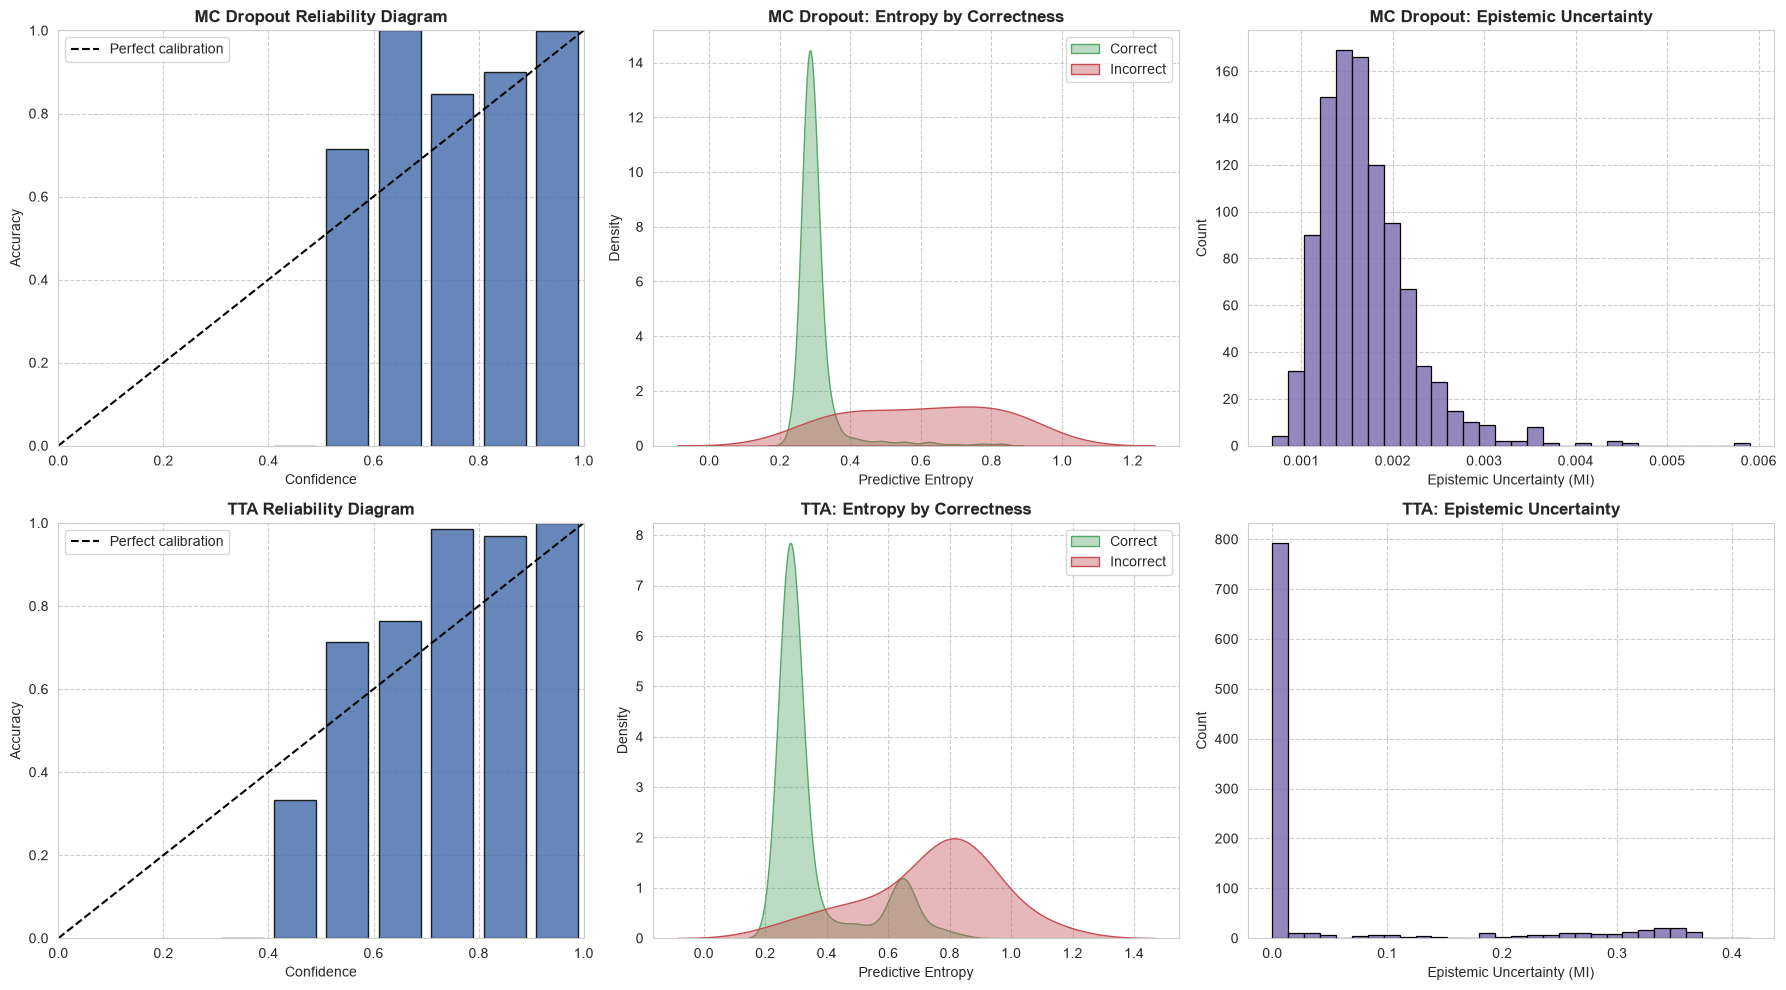

Saved: FetleSwinHybrid_uncertainty2_figures.png / .pdf


In [ ]:
# ============================================================
# EXECUTION
# ============================================================
IMAGE_SIZE = 224
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

data_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

test_dataset.transform = data_transform
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=0
)

class_names = [k for k, v in sorted(label_mapping.items(), key=lambda x: x[1])]

results = run_uncertainty_analysis(
    model=model,
    dataloader=test_loader,
    tta_dataset=test_dataset,
    device=device,
    class_names=class_names,
    mean=mean,
    std=std,
    mc_samples=30,
    save_prefix="FetleSwinHybrid_uncertainty2",
)

In [24]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, 
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE
import matplotlib.gridspec as gridspec
import numpy as np
import torch
class_names = [k for k, v in sorted(label_mapping.items(), key=lambda x: x[1])]

def evaluate_model_with_metrics_and_separate_plots(
    model, dataloader, device, class_names=class_names):
    model.eval()
    all_labels, all_preds, all_probs, all_confs, all_features = [], [], [], [], []
    misclassified_imgs, misclassified_trues, misclassified_preds, misclassified_confs = [], [], [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            
            probs = torch.softmax(outputs, dim=1)
            confs, preds = torch.max(probs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_confs.extend(confs.cpu().numpy())
            all_features.extend(outputs.cpu().numpy())

            # Collect up to 3 misclassified samples
            batch_labels = labels.cpu().numpy()
            batch_preds = preds.cpu().numpy()
            batch_confs = confs.cpu().numpy()
            batch_inputs = inputs.cpu().numpy()
            
            for i in range(len(batch_labels)):
                if batch_labels[i] != batch_preds[i] and len(misclassified_imgs) < 3:
                    misclassified_imgs.append(batch_inputs[i])
                    misclassified_trues.append(batch_labels[i])
                    misclassified_preds.append(batch_preds[i])
                    misclassified_confs.append(batch_confs[i])

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_confs = np.array(all_confs)
    all_features = np.array(all_features)

    # ---------------------------------------------------------
    # 1. Base Metrics Computation
    # ---------------------------------------------------------
    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)
    kappa = cohen_kappa_score(all_labels, all_preds)

    try:
        n_classes = len(class_names)
        y_onehot = label_binarize(all_labels, classes=list(range(n_classes)))
        pr_auc = average_precision_score(y_onehot, all_probs, average="weighted")
    except Exception:
        pr_auc = float('nan')

    cm = confusion_matrix(all_labels, all_preds)
    specificity_per_class = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_per_class.append(spec)
    specificity = np.average(specificity_per_class)

    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")

    correct_mask = (all_labels == all_preds)
    misclassified_mask = (all_labels != all_preds)

    # ---------------------------------------------------------
    # 2. Figure 1: Misclassified Images Grid (600 DPI)
    # ---------------------------------------------------------
    if len(misclassified_imgs) > 0:
        fig1, axes = plt.subplots(1, len(misclassified_imgs), figsize=(4 * len(misclassified_imgs), 4))
        if len(misclassified_imgs) == 1:
            axes = [axes]
            
        for i, ax in enumerate(axes):
            img = misclassified_imgs[i]
            if img.ndim == 3 and img.shape[0] in [1, 3]:
                img = np.transpose(img, (1, 2, 0))
            img = (img - img.min()) / (img.max() - img.min() + 1e-8)
            
            ax.imshow(img.squeeze(), cmap='gray' if (img.ndim == 2 or img.shape[-1] == 1) else None)
            t_class = class_names[misclassified_trues[i]]
            p_class = class_names[misclassified_preds[i]]
            conf = misclassified_confs[i]
            
            ax.set_title(f"True: {t_class}\nPred: {p_class}\nConf: {conf:.4f}", fontsize=10, fontweight='bold')
            ax.axis('off')
            
        plt.tight_layout()
        plt.savefig('misclassified_images1.png', dpi=600, bbox_inches='tight')
        plt.show()

    # ---------------------------------------------------------
    # 3. Figure 2: Prediction Confidence Boxplot (600 DPI)
    # ---------------------------------------------------------
    fig2, ax_box = plt.subplots(figsize=(6, 5))
    correct_confs = all_confs[correct_mask]
    misclass_confs = all_confs[misclassified_mask]
    
    data_to_plot = [correct_confs]
    tick_labels = ['Correct']
    if len(misclass_confs) > 0:
        data_to_plot.append(misclass_confs)
        tick_labels.append('Misclassified')
        
    ax_box.boxplot(data_to_plot, showmeans=True)
    ax_box.set_xticks(range(1, len(tick_labels) + 1))
    ax_box.set_xticklabels(tick_labels, fontweight='bold')
    ax_box.set_title('Prediction Confidence: Correct vs Misclassified Images', fontsize=11, fontweight='bold')
    ax_box.set_ylabel('Prediction Confidence')
    ax_box.grid(True, axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('prediction_confidence_boxplot1.png', dpi=600, bbox_inches='tight')
    plt.show()

    # ---------------------------------------------------------
    # 4. Figure 3: t-SNE Feature Space Scatter Plot (600 DPI)
    # ---------------------------------------------------------
    fig3, ax_tsne = plt.subplots(figsize=(6.5, 5))
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, max(5, len(all_features) - 1)))
    tsne_results = tsne.fit_transform(all_features)
    
    ax_tsne.scatter(
        tsne_results[correct_mask, 0], tsne_results[correct_mask, 1], 
        alpha=0.6, label='Correct', marker='o', edgecolors='none', s=25
    )
    if np.any(misclassified_mask):
        ax_tsne.scatter(
            tsne_results[misclassified_mask, 0], tsne_results[misclassified_mask, 1], 
            alpha=0.9, label='Misclassified', marker='x', color='red', s=40
        )
    
    ax_tsne.set_title('t-SNE Feature Space: Correct vs Misclassified Predictions', fontsize=11, fontweight='bold')
    ax_tsne.set_xlabel('t-SNE Dimension 1')
    ax_tsne.set_ylabel('t-SNE Dimension 2')
    ax_tsne.legend()
    ax_tsne.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('tsne_feature_space1.png', dpi=600, bbox_inches='tight')
    plt.show()

Accuracy:    0.98905
Recall:      0.98745
Precision:   0.98371
F1 Score:    0.98555
MCC:         0.98240
PR AUC:      0.99758
Kappa:       0.98239
Specificity: 0.99476


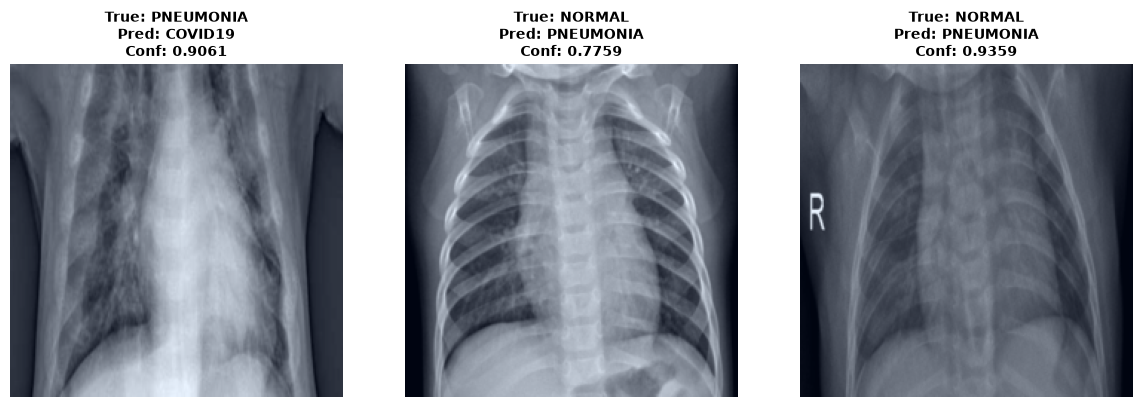

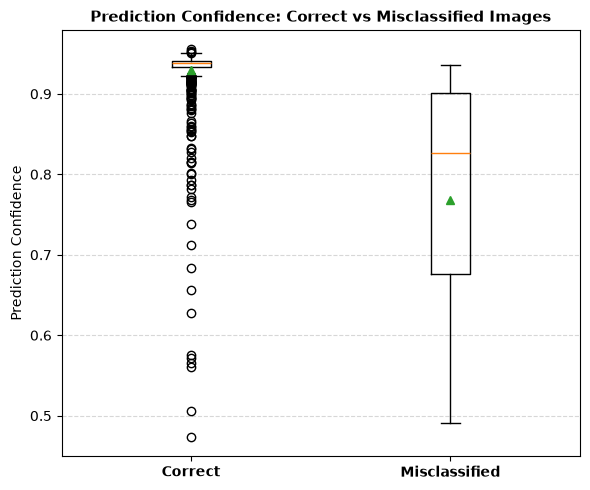

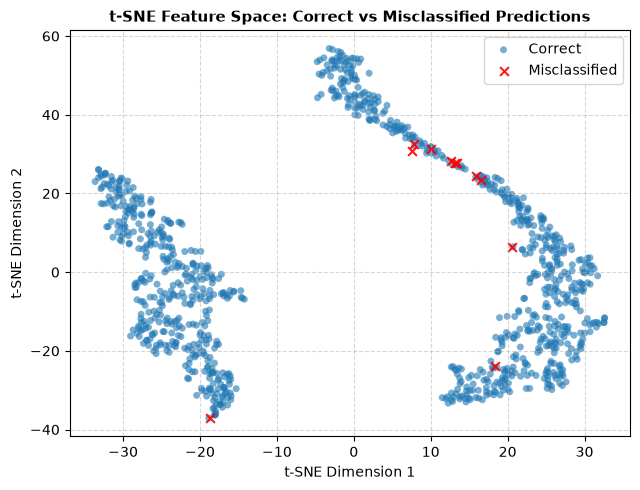

In [25]:
evaluate_model_with_metrics_and_separate_plots(model, test_loader, device, class_names=class_names)

# Cross-Validation Result of FeLASwin-Net

Full dataset: 10048 images across 3 classes
Running 5-fold CV with online augmentation (no held-out test set)

FOLD 5/5  (train=8039, val=2009)

Epoch 1/30
------------------------------


Validation Loss: 0.7931, Validation Accuracy: 0.7013
Training Loss: 0.9405, Training Accuracy: 0.6238

Epoch 2/30
------------------------------


Validation Loss: 0.5340, Validation Accuracy: 0.8805
Training Loss: 0.6099, Training Accuracy: 0.8329

Epoch 3/30
------------------------------


Validation Loss: 0.4421, Validation Accuracy: 0.9293
Training Loss: 0.4663, Training Accuracy: 0.9186

Epoch 4/30
------------------------------


Validation Loss: 0.3979, Validation Accuracy: 0.9532
Training Loss: 0.4240, Training Accuracy: 0.9418

Epoch 5/30
------------------------------


Validation Loss: 0.4123, Validation Accuracy: 0.9423
Training Loss: 0.4001, Training Accuracy: 0.9478
Patience Counter: 1/7

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.3301, Validation Accuracy: 0.9831
Training Loss: 0.3313, Training Accuracy: 0.9808
Patience Counter: 4/7

Epoch 28/30
------------------------------


Validation Loss: 0.3296, Validation Accuracy: 0.9821
Training Loss: 0.3308, Training Accuracy: 0.9806
Patience Counter: 5/7

Epoch 29/30
------------------------------


Validation Loss: 0.3285, Validation Accuracy: 0.9801
Training Loss: 0.3308, Training Accuracy: 0.9817
Patience Counter: 6/7

Epoch 30/30
------------------------------


Validation Loss: 0.3292, Validation Accuracy: 0.9821
Training Loss: 0.3295, Training Accuracy: 0.9822
Patience Counter: 7/7
Early stopping triggered at epoch 30.


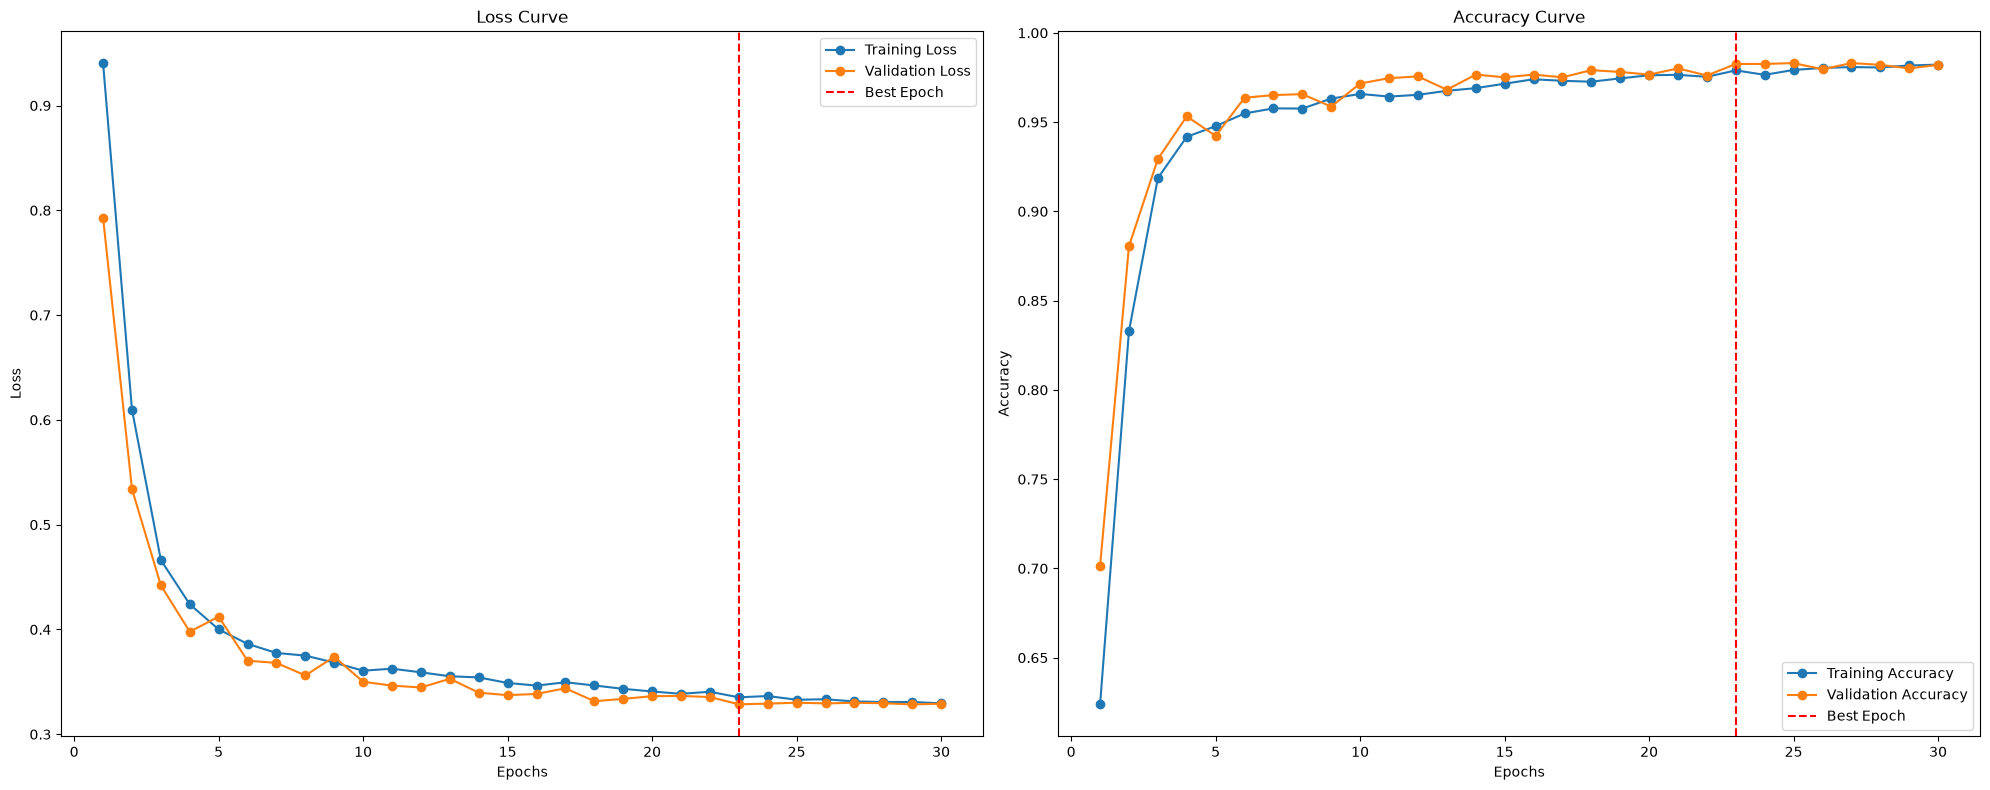


Training Report:
Total training time: 00:14:40
Total epochs run: 30
Best Training Loss: 0.3353 at epoch 23
Best Training Accuracy: 0.9790

Validation Report:
Best Validation Loss: 0.3286 at epoch 23
Best Validation Accuracy: 0.9826
Final Validation Loss: 0.3292
Final Validation Accuracy: 0.9821

Inference Report:
Total Inference Time (Validation only): 00:04:50
Accuracy:    0.98208
Recall:      0.97403
Precision:   0.97584
F1 Score:    0.97493
MCC:         0.97110
PR AUC:      0.99610
Kappa:       0.97110
Specificity: 0.99101
Saved fold 5 checkpoint -> fetleswinhybrid_fold5.pth


In [38]:
import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset


# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
RANDOM_STATE       = 42
NUM_EPOCHS         = 30
WARMUP_EPOCHS      = 3
PATIENCE           = 7
MIN_DELTA          = 0.001
BASE_LR            = 1e-4
WEIGHT_DECAY       = 0.03      # matches get_parameter_groups default below
BATCH_SIZE         = 32
NUM_WORKERS        = 4
IMAGE_SIZE         = 224

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS — updated to match your new pipeline
# ──────────────────────────────────────────────────────────────────────────
train_transform = transforms.Compose([
    # 1. Downsample 512x512 pre-cropped images to target model input
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    # 2. Subtle spatial transformations (mimics slight patient positioning differences)
    transforms.RandomAffine(
        degrees=[-5, 5],
        translate=(0.05, 0.05),
        scale=[0.95, 1.05]
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    # 3. Convert PIL Image to PyTorch Tensor
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.2,
        scale=(0.01, 0.05),
        ratio=(0.3, 3.3),
        value=0
    ),
    # 4. Normalization
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation & test transform — deterministic, no augmentation
val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV with online augmentation (no held-out test set)")


# ──────────────────────────────────────────────────────────────────────────
# PARAMETER GROUPING — matches your new training script exactly
# ──────────────────────────────────────────────────────────────────────────
def get_parameter_groups(model, weight_decay=0.03):
    no_decay = ['bias', 'LayerNorm', 'BatchNorm', 'norm', 'gamma']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0
        }
    ]
    return grouped_parameters


# ──────────────────────────────────────────────────────────────────────────
# MODEL BUILDER — fresh FetleSwinHybrid instance per fold
# ──────────────────────────────────────────────────────────────────────────
def build_model(num_classes, device):
    model = FetleSwinHybrid(
        num_classes=num_classes,
        drop_path_rate=0.05,
        attn_drop_rate=0.01
    ).to(device)
    return model


# ──────────────────────────────────────────────────────────────────────────
# OPTIMIZER / SCHEDULER BUILDER — fresh instance needed every fold
# ──────────────────────────────────────────────────────────────────────────
def build_optimizer_scheduler(model):
    optimizer = optim.AdamW(
        get_parameter_groups(model, weight_decay=WEIGHT_DECAY),
        lr=BASE_LR
    )

    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.05, end_factor=1.0, total_iters=WARMUP_EPOCHS
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer, T_max=(NUM_EPOCHS - WARMUP_EPOCHS), eta_min=1e-6
    )
    scheduler = SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[WARMUP_EPOCHS]
    )
    return optimizer, scheduler


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    fold_train_labels = fold_train_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    # Training set: online augmentation transform
    fold_train_dataset = CustomImageDataset(
        fold_train_df['filepaths'].values, fold_train_labels, transform=train_transform
    )

    # Validation set: deterministic transform (fixed variable name — was val_transform, now val_test_transform)
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=val_test_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # Fresh model, optimizer, scheduler for THIS fold
    model = build_model(num_classes, device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, scheduler = build_optimizer_scheduler(model)

    # Training
    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    # Evaluation
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None. Ensure it returns a dictionary "
            "of metrics like {'accuracy': 0.95, ...} so they can be aggregated."
        )

    # Save fold checkpoint
    checkpoint_path = f"fetleswinhybrid_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # Cleanup memory
    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP
# ──────────────────────────────────────────────────────────────────────────
# skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# fold_results = []
# for fold_idx, (train_idx, val_idx) in enumerate(
#     skf.split(df['filepaths'], df['labels']), start=1
# ):
#     fold_train_df = df.iloc[train_idx].reset_index(drop=True)
#     fold_val_df = df.iloc[val_idx].reset_index(drop=True)

#     metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
#     metrics["fold"] = fold_idx
#     fold_results.append(metrics)


# # ──────────────────────────────────────────────────────────────────────────
# # AGGREGATE RESULTS
# # ──────────────────────────────────────────────────────────────────────────
# def summarize_cv_results(fold_results):
#     results_df = pd.DataFrame(fold_results).set_index("fold")
#     summary = results_df.agg(['mean', 'std'])

#     print("\nPer-fold results:")
#     print(results_df.round(4).to_string())
#     print(f"\nMean ± Std across {len(results_df)} folds:")
#     for col in results_df.columns:
#         print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

#     return results_df, summary

# cv_results_df, cv_summary = summarize_cv_results(fold_results)
# cv_results_df.to_csv("cv_fold_results_pneumonia.csv")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df['filepaths'], df['labels']), start=1
):
    # Skip folds 1, 4, and 5
    if fold_idx not in [5]:
        continue

    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)

In [14]:
import gc
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset

# Ensure FetleSwinHybrid and evaluate_model_with_metrics are imported from your module
# from my_module import FetleSwinHybrid, evaluate_model_with_metrics

# ──────────────────────────────────────────────────────────────────────────
# CONFIG (Must match your cross-validation settings exactly)
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS = 5
RANDOM_STATE = 42
BATCH_SIZE = 32
NUM_WORKERS = 4
IMAGE_SIZE = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS & LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
val_test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

# Assuming df is loaded here
# df = pd.read_csv('...')

label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(
    f"Full dataset: {len(df)} images across {num_classes} classes"
)


# ──────────────────────────────────────────────────────────────────────────
# MODEL BUILDER
# ──────────────────────────────────────────────────────────────────────────
def build_model(num_classes, device):
    model = FetleSwinHybrid(
        num_classes=num_classes, drop_path_rate=0.05, attn_drop_rate=0.01
    ).to(device)
    return model


# ──────────────────────────────────────────────────────────────────────────
# EVALUATION LOOP ACROSS SAVED CHECKPOINTS
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)

fold_results = []

print(f"\nEvaluating saved checkpoints across {N_FOLDS} folds...")

for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    checkpoint_path = f"fetleswinhybrid_fold{fold_idx}.pth"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint file not found: {checkpoint_path}. Ensure all .pth files are in the working directory."
        )

    print(
        f"\n{'='*70}\nEVALUATING FOLD {fold_idx}/{N_FOLDS}"
        f"  (checkpoint: {checkpoint_path})\n{'='*70}"
    )

    # Re-create validation split using the exact same RANDOM_STATE
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)
    fold_val_labels = fold_val_df["labels"].map(label_mapping).values

    # Validation DataLoader (Deterministic transform)
    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=val_test_transform,
    )
    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # Build fresh model instance and load saved weights
    model = build_model(num_classes, device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()

    # Evaluate on the validation fold
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            f"evaluate_model_with_metrics returned None for Fold {fold_idx}."
        )

    fold_metrics["fold"] = fold_idx
    fold_results.append(fold_metrics)

    # Cleanup memory
    del model
    gc.collect()
    torch.cuda.empty_cache()


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE AND DISPLAY RESULTS
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(["mean", "std"])

    print("\n" + "=" * 70)
    print("                 CROSS-VALIDATION EVALUATION SUMMARY                 ")
    print("=" * 70)
    print("\nPer-fold results:")
    print(results_df.round(4).to_string())
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(
            f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}"
        )
    print("=" * 70 + "\n")

    return results_df, summary


cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv("cv_fold_results_fetleswinhybrid_eval.csv")

Full dataset: 10048 images across 3 classes

Evaluating saved checkpoints across 5 folds...

EVALUATING FOLD 1/5  (checkpoint: fetleswinhybrid_fold1.pth)
Accuracy:    0.98259
Recall:      0.98168
Precision:   0.97160
F1 Score:    0.97638
MCC:         0.97215
PR AUC:      0.99704
Kappa:       0.97202
Specificity: 0.99212

EVALUATING FOLD 2/5  (checkpoint: fetleswinhybrid_fold2.pth)
Accuracy:    0.96915
Recall:      0.96180
Precision:   0.95404
F1 Score:    0.95776
MCC:         0.95046
PR AUC:      0.99269
Kappa:       0.95040
Specificity: 0.98532

EVALUATING FOLD 3/5  (checkpoint: fetleswinhybrid_fold3.pth)
Accuracy:    0.98259
Recall:      0.97972
Precision:   0.97256
F1 Score:    0.97601
MCC:         0.97207
PR AUC:      0.99734
Kappa:       0.97200
Specificity: 0.99193

EVALUATING FOLD 4/5  (checkpoint: fetleswinhybrid_fold4.pth)
Accuracy:    0.98009
Recall:      0.97508
Precision:   0.97154
F1 Score:    0.97328
MCC:         0.96796
PR AUC:      0.99589
Kappa:       0.96795
Specifici

# Cross-Validation Result of DenseNet169"

In [12]:
import gc
import os
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import StratifiedKFold
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
MODEL_NAME = "densenet169"
PRETRAINED = False
N_FOLDS = 5
RANDOM_STATE = 42
NUM_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 0.001
BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 32
NUM_WORKERS = 4
IMAGE_SIZE = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS
# ──────────────────────────────────────────────────────────────────────────
train_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomAffine(
            degrees=[-5, 5], translate=(0.05, 0.05), scale=[0.95, 1.05]
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.RandomErasing(
            p=0.2, scale=(0.01, 0.05), ratio=(0.3, 3.3), value=0
        ),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

val_test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
# Assuming df is loaded here
# df = pd.read_csv('...')

label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(
    f"Running {N_FOLDS}-fold CV on {MODEL_NAME} with online augmentation"
)


# ──────────────────────────────────────────────────────────────────────────
# MODEL BUILDER
# ──────────────────────────────────────────────────────────────────────────
def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)

    if hasattr(model, "classifier"):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, "fc"):
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, "head"):
        in_features = model.head.in_features
        model.head = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError(f"Unexpected classifier layer structure in {model_name}")

    return model


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(
        f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
        f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}"
    )

    fold_train_labels = fold_train_df["labels"].map(label_mapping).values
    fold_val_labels = fold_val_df["labels"].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_df["filepaths"].values,
        fold_train_labels,
        transform=train_transform,
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=val_test_transform,
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # Fresh model, criterion, optimizer, and scheduler for this fold
    model = load_model(
        MODEL_NAME, num_classes=num_classes, pretrained=PRETRAINED
    ).to(device)

    # Note: Using NLLLoss because load_model includes LogSoftmax in the output layer
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY
    )
    scheduler = CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
    )

    # Training
    train_model(
        model,
        fold_train_loader,
        fold_val_loader,
        criterion,
        optimizer,
        scheduler,
        num_epochs=NUM_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA,
    )

    # Evaluation
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None. Ensure it returns a dictionary of metrics."
        )

    # Save fold checkpoint
    checkpoint_path = f"Base{MODEL_NAME}_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # Cleanup memory
    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# skf = StratifiedKFold(
#     n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
# )

# fold_results = []
# for fold_idx, (train_idx, val_idx) in enumerate(
#     skf.split(df["filepaths"], df["labels"]), start=1
# ):
#     fold_train_df = df.iloc[train_idx].reset_index(drop=True)
#     fold_val_df = df.iloc[val_idx].reset_index(drop=True)

#     metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
#     metrics["fold"] = fold_idx
#     fold_results.append(metrics)


# # ──────────────────────────────────────────────────────────────────────────
# # AGGREGATE RESULTS
# # ──────────────────────────────────────────────────────────────────────────
# def summarize_cv_results(fold_results):
#     results_df = pd.DataFrame(fold_results).set_index("fold")
#     summary = results_df.agg(["mean", "std"])

#     print("\nPer-fold results:")
#     print(results_df.round(4).to_string())
#     print(f"\nMean ± Std across {len(results_df)} folds:")
#     for col in results_df.columns:
#         print(
#             f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}"
#         )

#     return results_df, summary


# cv_results_df, cv_summary = summarize_cv_results(fold_results)
# cv_results_df.to_csv(f"cv_fold_results_pneumonia_{MODEL_NAME}.csv")

Full dataset: 10048 images across 3 classes
Running 5-fold CV on densenet169 with online augmentation


In [14]:
import gc
import os
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset

# Ensure evaluate_model_with_metrics is available in your scope
# from my_module import evaluate_model_with_metrics

# ──────────────────────────────────────────────────────────────────────────
# CONFIG (Must match training settings exactly)
# ──────────────────────────────────────────────────────────────────────────
MODEL_NAME = "densenet169"
PRETRAINED = False
N_FOLDS = 5
RANDOM_STATE = 42
BATCH_SIZE = 32
NUM_WORKERS = 4
IMAGE_SIZE = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS & LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
val_test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

# Assuming df is already loaded in your environment
label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")


# ──────────────────────────────────────────────────────────────────────────
# MODEL BUILDER
# ──────────────────────────────────────────────────────────────────────────
def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)

    if hasattr(model, "classifier"):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "fc"):
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "head"):
        in_features = model.head.in_features
        model.head = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    else:
        raise ValueError(
            f"Unexpected classifier layer structure in {model_name}"
        )

    return model


# ──────────────────────────────────────────────────────────────────────────
# EVALUATION LOOP ACROSS SAVED CHECKPOINTS
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)

fold_results = []

print(f"\nEvaluating saved {MODEL_NAME} checkpoints across {N_FOLDS} folds...")

for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    checkpoint_path = f"{MODEL_NAME}_fold{fold_idx}.pth"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint file not found: {checkpoint_path}. Ensure all .pth files are in the working directory."
        )

    print(
        f"\n{'='*70}\nEVALUATING FOLD {fold_idx}/{N_FOLDS}"
        f"  (checkpoint: {checkpoint_path})\n{'='*70}"
    )

    # Re-create validation split using exact same RANDOM_STATE
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)
    fold_val_labels = fold_val_df["labels"].map(label_mapping).values

    # Validation DataLoader (Deterministic transform)
    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=val_test_transform,
    )
    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # Build model architecture and load saved checkpoint weights
    model = load_model(
        MODEL_NAME, num_classes=num_classes, pretrained=PRETRAINED
    ).to(device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()

    # Evaluate on the validation fold
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            f"evaluate_model_with_metrics returned None for Fold {fold_idx}."
        )

    fold_metrics["fold"] = fold_idx
    fold_results.append(fold_metrics)

    # Memory cleanup
    del model
    gc.collect()
    torch.cuda.empty_cache()


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE AND DISPLAY RESULTS
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(["mean", "std"])

    print("\n" + "=" * 70)
    print(
        f"         CROSS-VALIDATION EVALUATION SUMMARY ({MODEL_NAME.upper()})         "
    )
    print("=" * 70)
    print("\nPer-fold results:")
    print(results_df.round(4).to_string())
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(
            f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}"
        )
    print("=" * 70 + "\n")

    return results_df, summary


cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv(f"cv_fold_results_pneumonia_{MODEL_NAME}_eval.csv")

Full dataset: 10048 images across 3 classes

Evaluating saved densenet169 checkpoints across 5 folds...

EVALUATING FOLD 1/5  (checkpoint: densenet169_fold1.pth)
Accuracy:    0.97960
Recall:      0.97734
Precision:   0.96794
F1 Score:    0.97242
MCC:         0.96732
PR AUC:      0.99716
Kappa:       0.96722
Specificity: 0.99057

EVALUATING FOLD 2/5  (checkpoint: densenet169_fold2.pth)
Accuracy:    0.97164
Recall:      0.96772
Precision:   0.95860
F1 Score:    0.96296
MCC:         0.95450
PR AUC:      0.99137
Kappa:       0.95442
Specificity: 0.98641

EVALUATING FOLD 3/5  (checkpoint: densenet169_fold3.pth)
Accuracy:    0.98010
Recall:      0.97578
Precision:   0.96983
F1 Score:    0.97271
MCC:         0.96804
PR AUC:      0.99785
Kappa:       0.96799
Specificity: 0.99059

EVALUATING FOLD 4/5  (checkpoint: densenet169_fold4.pth)
Accuracy:    0.97511
Recall:      0.96583
Precision:   0.96918
F1 Score:    0.96743
MCC:         0.95994
PR AUC:      0.99486
Kappa:       0.95984
Specificity: 

# MC Nemar's Test Result

In [16]:
import gc
import os
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from statsmodels.stats.contingency_tables import mcnemar
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset

# Ensure FetleSwinHybrid is available in your environment/module
# from my_module import FetleSwinHybrid

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
PROPOSED_MODEL_NAME = "FetleSwinHybrid"
BASELINE_MODEL_NAME = "densenet169"
N_FOLDS = 5
RANDOM_STATE = 42
BATCH_SIZE = 32
NUM_WORKERS = 4
IMAGE_SIZE = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS
# ──────────────────────────────────────────────────────────────────────────
val_test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING (Auto-detect label column)
# ──────────────────────────────────────────────────────────────────────────
# Assuming df is loaded in your environment (e.g., df = pd.read_csv('...'))

possible_label_cols = ["labels", "label", "class", "target", "category"]
label_col = next((col for col in possible_label_cols if col in df.columns), None)

if label_col is None:
    raise KeyError(
        f"Could not find label column. Available columns in df: {list(df.columns)}"
    )

if label_col != "labels":
    df = df.rename(columns={label_col: "labels"})
    print(f"Auto-detected and renamed column '{label_col}' -> 'labels'")

label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")


# ──────────────────────────────────────────────────────────────────────────
# MODEL LOADERS
# ──────────────────────────────────────────────────────────────────────────
def load_proposed_model(num_classes, device):
    """Instantiates proposed FetleSwinHybrid model."""
    model = FetleSwinHybrid(
        num_classes=num_classes, drop_path_rate=0.05, attn_drop_rate=0.01
    ).to(device)
    return model


def load_densenet_model(model_name, num_classes, pretrained=False):
    """Instantiates baseline DenseNet model matching training setup."""
    model = timm.create_model(model_name, pretrained=pretrained)

    if hasattr(model, "classifier"):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "fc"):
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "head"):
        in_features = model.head.in_features
        model.head = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    else:
        raise ValueError(
            f"Unexpected classifier layer structure in {model_name}"
        )

    return model


# ──────────────────────────────────────────────────────────────────────────
# PREDICTION EXTRACTION FUNCTION
# ──────────────────────────────────────────────────────────────────────────
@torch.no_grad()
def get_model_predictions(model, dataloader, device="cuda"):
    """Collects ground-truth targets and predicted class indices."""
    model.to(device)
    model.eval()

    all_preds = []
    all_targets = []

    for images, targets in dataloader:
        images = images.to(device)
        outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

    return np.array(all_targets), np.array(all_preds)


# ──────────────────────────────────────────────────────────────────────────
# MCNEMAR TEST OOF EVALUATION LOOP
# ──────────────────────────────────────────────────────────────────────────
oof_y_true = []
oof_pred_proposed = []
oof_pred_densenet = []

skf = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)

print(
    f"\nCollecting Out-Of-Fold predictions for McNemar's Test ({PROPOSED_MODEL_NAME} vs {BASELINE_MODEL_NAME})..."
)

for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    proposed_ckpt = f"fetleswinhybrid_fold{fold_idx}.pth"
    densenet_ckpt = f"{BASELINE_MODEL_NAME}_fold{fold_idx}.pth"

    if not os.path.exists(proposed_ckpt) or not os.path.exists(densenet_ckpt):
        raise FileNotFoundError(
            f"Missing checkpoint file for Fold {fold_idx}. Ensure {proposed_ckpt} and {densenet_ckpt} exist."
        )

    print(f"Evaluating Fold {fold_idx}/{N_FOLDS}...")

    # Re-create validation fold dataset
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)
    val_labels = fold_val_df["labels"].map(label_mapping).values

    val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        val_labels,
        transform=val_test_transform,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # 1. Evaluate Proposed Model
    proposed_model = load_proposed_model(num_classes, device)
    proposed_model.load_state_dict(
        torch.load(proposed_ckpt, map_location=device)
    )
    _, preds_prop = get_model_predictions(
        proposed_model, val_loader, device=device
    )

    del proposed_model
    gc.collect()
    torch.cuda.empty_cache()

    # 2. Evaluate Baseline Model (DenseNet169)
    densenet_model = load_densenet_model(
        BASELINE_MODEL_NAME, num_classes=num_classes, pretrained=False
    ).to(device)
    densenet_model.load_state_dict(
        torch.load(densenet_ckpt, map_location=device)
    )
    _, preds_dense = get_model_predictions(
        densenet_model, val_loader, device=device
    )

    del densenet_model
    gc.collect()
    torch.cuda.empty_cache()

    # Store OOF predictions
    oof_y_true.extend(val_labels)
    oof_pred_proposed.extend(preds_prop)
    oof_pred_densenet.extend(preds_dense)


# ──────────────────────────────────────────────────────────────────────────
# STATISTICAL ANALYSIS & CONTINGENCY TABLE
# ──────────────────────────────────────────────────────────────────────────
y_true = np.array(oof_y_true)
correct_proposed = np.array(oof_pred_proposed) == y_true
correct_densenet = np.array(oof_pred_densenet) == y_true

# Matrix Cells
n00 = np.sum(correct_proposed & correct_densenet)
n01 = np.sum(
    correct_proposed & ~correct_densenet
)  # Proposed correct, DenseNet wrong
n10 = np.sum(
    ~correct_proposed & correct_densenet
)  # Proposed wrong, DenseNet correct
n11 = np.sum(~correct_proposed & ~correct_densenet)

contingency_table = [[n00, n01], [n10, n11]]

# Dynamic exact parameter based on total discordant counts
discordant_sum = n01 + n10
use_exact = discordant_sum < 25

result = mcnemar(contingency_table, exact=use_exact, correction=True)

df_table = pd.DataFrame(
    contingency_table,
    index=[f"{PROPOSED_MODEL_NAME} Correct", f"{PROPOSED_MODEL_NAME} Incorrect"],
    columns=[
        f"{BASELINE_MODEL_NAME} Correct",
        f"{BASELINE_MODEL_NAME} Incorrect",
    ],
)

print(
    "\n========================================================================="
)
print(
    "            MCNEMAR'S TEST ON AGGREGATED OUT-OF-FOLD (OOF) DATA          "
)
print(
    "========================================================================="
)
print("\n2x2 Contingency Table:")
print(df_table.to_string())
print("-" * 73)
print(f"Total OOF Samples Analyzed (N)      : {len(y_true)}")
print(f"{PROPOSED_MODEL_NAME} Correct / {BASELINE_MODEL_NAME} Wrong : {n01}")
print(f"{PROPOSED_MODEL_NAME} Wrong / {BASELINE_MODEL_NAME} Correct : {n10}")
print(f"Total Discordant Samples (n01 + n10): {discordant_sum}")

if not use_exact:
    print(f"Chi-Squared Statistic (χ²)          : {result.statistic:.4f}")

print(
    f"p-value                             : {result.pvalue:.6e} ({'Exact Binomial' if use_exact else 'Chi-Square with Edwards Continuity Correction'})"
)
print("-" * 73)

if result.pvalue < 0.05:
    print(
        f"Result: STATISTICALLY SIGNIFICANT DIFFERENCE (p < 0.05)\n"
        f"Interpretation: {PROPOSED_MODEL_NAME} demonstrates statistically significant\n"
        f"performance gains over {BASELINE_MODEL_NAME}."
    )
else:
    print(
        f"Result: NO STATISTICALLY SIGNIFICANT DIFFERENCE (p >= 0.05)\n"
        f"Interpretation: Performance difference between models is not statistically significant."
    )
print(
    "=========================================================================\n"
)

# Save OOF predictions to CSV for record keeping
oof_df = pd.DataFrame(
    {
        "y_true": y_true,
        f"pred_{PROPOSED_MODEL_NAME}": oof_pred_proposed,
        f"pred_{BASELINE_MODEL_NAME}": oof_pred_densenet,
    }
)
oof_df.to_csv(
    f"mcnemar_oof_predictions_{PROPOSED_MODEL_NAME}_vs_{BASELINE_MODEL_NAME}.csv",
    index=False,
)

Full dataset: 10048 images across 3 classes

Evaluating Fold 1/5...
Evaluating Fold 2/5...
Evaluating Fold 3/5...
Evaluating Fold 4/5...
Evaluating Fold 5/5...

            MCNEMAR'S TEST ON AGGREGATED OUT-OF-FOLD (OOF) DATA          

2x2 Contingency Table:
                           densenet169 Correct  densenet169 Incorrect
FetleSwinHybrid Correct                   9759                     81
FetleSwinHybrid Incorrect                   69                    139
-------------------------------------------------------------------------
Total OOF Samples Analyzed (N)      : 10048
FetleSwinHybrid Correct / densenet169 Wrong : 81
FetleSwinHybrid Wrong / densenet169 Correct : 69
Total Discordant Samples (n01 + n10): 150
Chi-Squared Statistic (χ²)          : 0.8067
p-value                             : 3.691076e-01 (Chi-Square with Edwards Continuity Correction)
-------------------------------------------------------------------------
Result: NO STATISTICALLY SIGNIFICANT DIFFERENCE (p >= 0

# Explainable AI Visualization Code

In [20]:
import csv
import random


from xai_cam import GradCAMPlusPlus, ScoreCAM, TransitionMatrixHeatmap, overlay_cam_on_image
from xai_metrics import deletion_insertion
from xai_visualize import plot_qualitative_grid, plot_deletion_insertion_curves


def _denormalize_to_01(img_chw, mean, std):
    if mean is None:
        return img_chw.clamp(0, 1)
    mean_t = torch.tensor(mean, device=img_chw.device).view(-1, 1, 1)
    std_t = torch.tensor(std, device=img_chw.device).view(-1, 1, 1)
    return (img_chw * std_t + mean_t).clamp(0, 1)


def _to_hwc_numpy(img_chw01):
    return img_chw01.permute(1, 2, 0).cpu().numpy()


def _index_by_class(dataset, num_classes):
    buckets = {c: [] for c in range(num_classes)}
    for i in range(len(dataset)):
        _, label = dataset[i]
        label = int(label)
        buckets[label].append(i)
    return buckets


def run_xai_evaluation(model, test_dataset, class_names, target_layer, device="cuda",
                       mean=None, std=None,
                       n_qual_samples_per_class=1,
                       n_quant_samples_per_class=8,
                       deletion_insertion_step_frac=0.02,
                       scorecam_max_channels=64,
                       save_dir="xai_outputs",
                       reshape_transform=None,
                       use_predicted_class=True,
                       seed=0, num_workers=0):
    """
    Runs qualitative & quantitative XAI evaluation across Grad-CAM++, Score-CAM,
    and Transition Matrix Heatmap.
    """
    os.makedirs(save_dir, exist_ok=True)
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    model.to(device)
    model.eval()
    num_classes = len(class_names)
    buckets = _index_by_class(test_dataset, num_classes)

    # ----------------------------------------------------------------
    # 1. QUALITATIVE: Grad-CAM++, Score-CAM, and Transition Matrix Heatmap
    # ----------------------------------------------------------------
    qual_samples = []
    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_qual_samples_per_class, len(idxs)))
        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            orig_hwc = _to_hwc_numpy(img_01)

            target_cls = None if use_predicted_class else int(label)

            # Grad-CAM++
            gradcam_pp = GradCAMPlusPlus(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, _, _ = gradcam_pp(img.unsqueeze(0), target_class=target_cls)
            gradcam_pp.remove_hooks()

            # Score-CAM
            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                max_channels=scorecam_max_channels)
            sc_cam, _, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # Transition Matrix Heatmap
            transcam = TransitionMatrixHeatmap(model, target_layer, reshape_transform=reshape_transform)
            tm_cam, _, _ = transcam(img.unsqueeze(0), target_class=target_cls)
            transcam.remove_hooks()

            gc_overlay = overlay_cam_on_image(orig_hwc, gc_cam[0])
            sc_overlay = overlay_cam_on_image(orig_hwc, sc_cam)
            tm_overlay = overlay_cam_on_image(orig_hwc, tm_cam[0])

            qual_samples.append({
                "class_name": class_names[c],
                "orig": orig_hwc,
                "gradcam_pp_overlay": gc_overlay,
                "scorecam_overlay": sc_overlay,
                "trans_heatmap_overlay": tm_overlay,
            })

    qual_path = os.path.join(save_dir, "qualitative_cam_grid1.png")
    plot_qualitative_grid(qual_samples, qual_path)

    # ----------------------------------------------------------------
    # 2. QUANTITATIVE: Deletion/Insertion Faithfulness AUC
    # ----------------------------------------------------------------
    per_class_results = {c: {
        "gradcam_pp_deletion_auc": [], "gradcam_pp_insertion_auc": [],
        "scorecam_deletion_auc": [], "scorecam_insertion_auc": [],
        "trans_heatmap_deletion_auc": [], "trans_heatmap_insertion_auc": [],
    } for c in range(num_classes)}

    per_class_mean_curves = {}

    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_quant_samples_per_class, len(idxs)))

        del_curves, ins_curves = [], []

        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            target_cls = None if use_predicted_class else int(label)

            # Grad-CAM++
            gradcam_pp = GradCAMPlusPlus(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam_pp(img.unsqueeze(0), target_class=target_cls)
            gradcam_pp.remove_hooks()
            gc_class = int(gc_class[0])

            # Score-CAM
            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # Transition Matrix Heatmap
            transcam = TransitionMatrixHeatmap(model, target_layer, reshape_transform=reshape_transform)
            tm_cam, tm_class, _ = transcam(img.unsqueeze(0), target_class=target_cls)
            transcam.remove_hooks()
            tm_class = int(tm_class[0])

            # Faithfulness Evaluation
            gc_res = deletion_insertion(model, img_01, gc_cam[0], gc_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)
            sc_res = deletion_insertion(model, img_01, sc_cam, sc_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)
            tm_res = deletion_insertion(model, img_01, tm_cam[0], tm_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)

            per_class_results[c]["gradcam_pp_deletion_auc"].append(gc_res["deletion_auc"])
            per_class_results[c]["gradcam_pp_insertion_auc"].append(gc_res["insertion_auc"])
            per_class_results[c]["scorecam_deletion_auc"].append(sc_res["deletion_auc"])
            per_class_results[c]["scorecam_insertion_auc"].append(sc_res["insertion_auc"])
            per_class_results[c]["trans_heatmap_deletion_auc"].append(tm_res["deletion_auc"])
            per_class_results[c]["trans_heatmap_insertion_auc"].append(tm_res["insertion_auc"])

            del_curves.append(gc_res["deletion_curve"])
            ins_curves.append(gc_res["insertion_curve"])

        if del_curves:
            min_len = min(len(x) for x in del_curves)
            del_stack = np.stack([x[:min_len] for x in del_curves])
            ins_stack = np.stack([x[:min_len] for x in ins_curves])
            per_class_mean_curves[class_names[c]] = {
                "deletion_curve": del_stack.mean(axis=0),
                "deletion_auc": float(np.mean(per_class_results[c]["gradcam_pp_deletion_auc"])),
                "insertion_curve": ins_stack.mean(axis=0),
                "insertion_auc": float(np.mean(per_class_results[c]["gradcam_pp_insertion_auc"])),
            }

    di_path = os.path.join(save_dir, "deletion_insertion_curves.png")
    plot_deletion_insertion_curves(per_class_mean_curves, di_path)

    # ----------------------------------------------------------------
    # 3. Aggregate + Write CSV + Print Paper-Ready Table
    # ----------------------------------------------------------------
    def summarize(values):
        arr = np.array(values, dtype=float)
        if len(arr) == 0:
            return None, None
        return float(arr.mean()), float(arr.std())

    csv_path = os.path.join(save_dir, "xai_quantitative_results.csv")
    fieldnames = ["class", 
                  "gradcam_pp_deletion_auc", "gradcam_pp_insertion_auc",
                  "scorecam_deletion_auc", "scorecam_insertion_auc",
                  "trans_heatmap_deletion_auc", "trans_heatmap_insertion_auc"]

    rows = []
    overall = {k: [] for k in fieldnames if k != "class"}

    for c in range(num_classes):
        r = per_class_results[c]
        row = {"class": class_names[c]}
        for key, values in [
            ("gradcam_pp_deletion_auc", r["gradcam_pp_deletion_auc"]),
            ("gradcam_pp_insertion_auc", r["gradcam_pp_insertion_auc"]),
            ("scorecam_deletion_auc", r["scorecam_deletion_auc"]),
            ("scorecam_insertion_auc", r["scorecam_insertion_auc"]),
            ("trans_heatmap_deletion_auc", r["trans_heatmap_deletion_auc"]),
            ("trans_heatmap_insertion_auc", r["trans_heatmap_insertion_auc"]),
        ]:
            m, s = summarize(values)
            row[key] = f"{m:.4f} ± {s:.4f}" if m is not None else "N/A"
            if m is not None:
                overall[key].extend(values)

        rows.append(row)

    overall_row = {"class": "OVERALL"}
    for key in fieldnames:
        if key == "class":
            continue
        if not overall[key]:
            overall_row[key] = "N/A"
        else:
            m, s = summarize(overall[key])
            overall_row[key] = f"{m:.4f} ± {s:.4f}"
    rows.append(overall_row)

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    print("\n=== XAI Quantitative Evaluation (paper-ready table) ===\n")
    header = "| Class | Del. AUC (GC++) | Ins. AUC (GC++) | Del. AUC (SC) | Ins. AUC (SC) | Del. AUC (TM) | Ins. AUC (TM) |"
    sep = "|---|---|---|---|---|---|---|"
    print(header)
    print(sep)
    for row in rows:
        line = f"| {row['class']} | {row['gradcam_pp_deletion_auc']} | {row['gradcam_pp_insertion_auc']} | " \
               f"{row['scorecam_deletion_auc']} | {row['scorecam_insertion_auc']} | " \
               f"{row['trans_heatmap_deletion_auc']} | {row['trans_heatmap_insertion_auc']} |"
        print(line)

    print(f"\nSaved: {qual_path}")
    print(f"Saved: {di_path}")
    print(f"Saved: {csv_path}")

    return {
        "qualitative_path": qual_path,
        "deletion_insertion_path": di_path,
        "csv_path": csv_path,
        "per_class_results": per_class_results,
        "rows": rows,
    }

In [17]:
print(label_mapping)

{'COVID19': 0, 'PNEUMONIA': 1, 'NORMAL': 2}


In [28]:
def swin_reshape_transform(x):
    """
    Transforms 3D sequence tokens (B, L, C) -> 4D spatial feature maps (B, C, H, W).
    For stage4_swin: L = 49, C = 256 -> reshapes to (B, 256, 7, 7).
    """
    if x.dim() == 3:
        B, L, C = x.shape
        H = W = int(L ** 0.5)  # 49 tokens -> 7x7 spatial resolution
        return x.transpose(1, 2).contiguous().view(B, C, H, W)
    return x
    
model.load_state_dict(torch.load("fetle_swin_hybrid_XRay.pth", map_location=device))
model.to(device)
model.eval()
# 1. Reordered class names to perfectly match your dataset mapping:
# 0: Healthy, 1: Yellow Mosaic, 2: Insect, 3: Cercospora leaf spot, 4: Leaf Crinkle
class_names = ["COVID19", "PNEUMONIA", "NORMAL"]
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

# 3. Target layer selection:
# We select `model.stage4_down` (AMSFA) because it outputs a standard 4D tensor (B, 256, 7, 7).
# This is directly compatible with Grad-CAM++, Score-CAM, and Transition Matrix Heatmap
# without requiring a reshape_transform.
target_layer = model.stage4_swin[-2]

# 5. Run evaluation with the reshape transform
results = run_xai_evaluation(
    model=model,
    test_dataset=test_dataset,
    class_names=class_names,
    target_layer=target_layer,
    device=device,
    mean=norm_mean,
    std=norm_std,
    n_qual_samples_per_class=1,
    n_quant_samples_per_class=8,
    deletion_insertion_step_frac=0.02,
    scorecam_max_channels=64,
    save_dir="xai_outputs_Pneu3",
    reshape_transform=swin_reshape_transform,
    use_predicted_class=True,
    seed=None,
    num_workers=0
)

Saved qualitative CAM grid to xai_outputs_Pneu3\qualitative_cam_grid1.png
Saved deletion/insertion curves to xai_outputs_Pneu3\deletion_insertion_curves.png

=== XAI Quantitative Evaluation (paper-ready table) ===

| Class | Del. AUC (GC++) | Ins. AUC (GC++) | Del. AUC (SC) | Ins. AUC (SC) | Del. AUC (TM) | Ins. AUC (TM) |
|---|---|---|---|---|---|---|
| COVID19 | 0.9397 ± 0.0023 | 0.9387 ± 0.0023 | 0.9399 ± 0.0021 | 0.9386 ± 0.0025 | 0.9374 ± 0.0080 | 0.9388 ± 0.0017 |
| PNEUMONIA | 0.5561 ± 0.1805 | 0.4819 ± 0.1476 | 0.3865 ± 0.1811 | 0.6935 ± 0.1630 | 0.6459 ± 0.1458 | 0.3770 ± 0.1416 |
| NORMAL | 0.6949 ± 0.3298 | 0.7853 ± 0.2589 | 0.7458 ± 0.2816 | 0.7881 ± 0.2565 | 0.6989 ± 0.3233 | 0.7732 ± 0.2719 |
| OVERALL | 0.7302 ± 0.2688 | 0.7353 ± 0.2562 | 0.6907 ± 0.2999 | 0.8067 ± 0.2024 | 0.7607 ± 0.2409 | 0.6963 ± 0.2948 |

Saved: xai_outputs_Pneu3\qualitative_cam_grid1.png
Saved: xai_outputs_Pneu3\deletion_insertion_curves.png
Saved: xai_outputs_Pneu3\xai_quantitative_results.csv



Epoch 1/30
------------------------------


Validation Loss: 0.4982, Validation Accuracy: 0.8965
Training Loss: 0.6569, Training Accuracy: 0.8352

Epoch 2/30
------------------------------


Validation Loss: 0.3943, Validation Accuracy: 0.9512
Training Loss: 0.4263, Training Accuracy: 0.9394

Epoch 3/30
------------------------------


Validation Loss: 0.3785, Validation Accuracy: 0.9602
Training Loss: 0.3898, Training Accuracy: 0.9517

Epoch 4/30
------------------------------


Validation Loss: 0.4170, Validation Accuracy: 0.9383
Training Loss: 0.3756, Training Accuracy: 0.9604
Patience Counter: 1/7

Epoch 5/30
------------------------------


Validation Loss: 0.4131, Validation Accuracy: 0.9393
Training Loss: 0.3532, Training Accuracy: 0.9708
Patience Counter: 2/7

Epoch 6/30
------------------------------


... (6 outputs left out)

Validation Loss: 0.3655, Validation Accuracy: 0.9622
Training Loss: 0.3127, Training Accuracy: 0.9918
Patience Counter: 4/7

Epoch 13/30
------------------------------


Validation Loss: 0.3714, Validation Accuracy: 0.9602
Training Loss: 0.3030, Training Accuracy: 0.9960
Patience Counter: 5/7

Epoch 14/30
------------------------------


Validation Loss: 0.3624, Validation Accuracy: 0.9701
Training Loss: 0.3086, Training Accuracy: 0.9925
Patience Counter: 6/7

Epoch 15/30
------------------------------


Validation Loss: 0.3646, Validation Accuracy: 0.9672
Training Loss: 0.3026, Training Accuracy: 0.9961
Patience Counter: 7/7
Early stopping triggered at epoch 15.


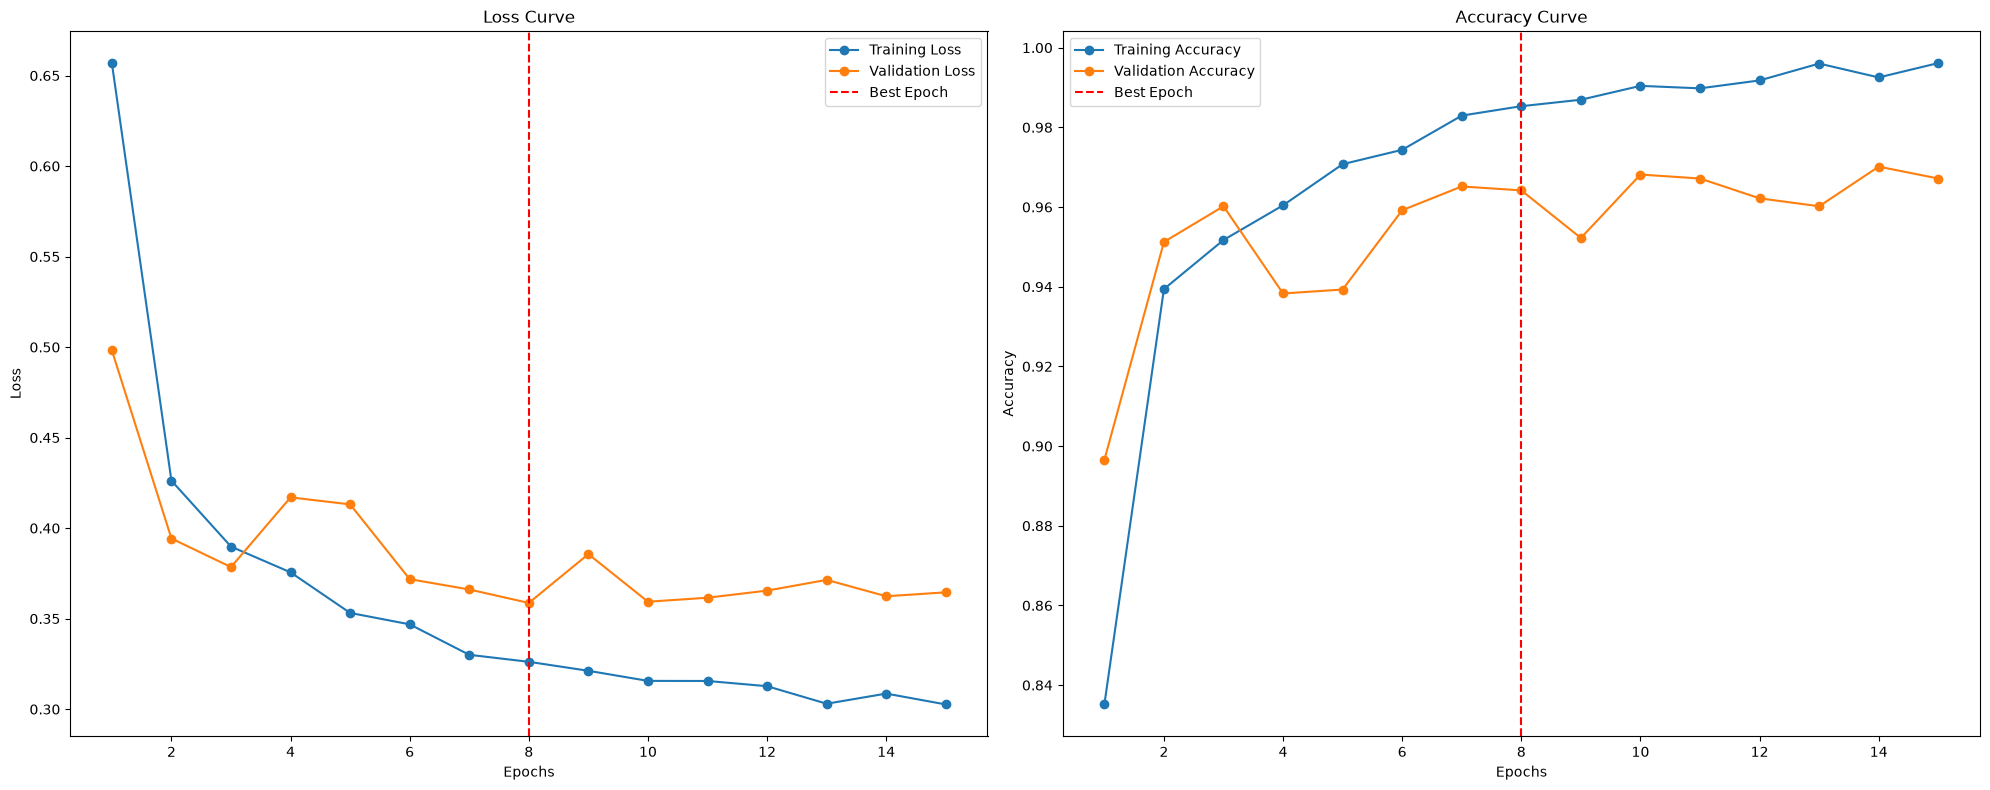


Training Report:
Total training time: 00:05:51
Total epochs run: 15
Best Training Loss: 0.3262 at epoch 8
Best Training Accuracy: 0.9853

Validation Report:
Best Validation Loss: 0.3587 at epoch 8
Best Validation Accuracy: 0.9642
Final Validation Loss: 0.3646
Final Validation Accuracy: 0.9672

Inference Report:
Total Inference Time (Validation only): 00:01:04


In [19]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=7, min_delta=0.001)

In [20]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98209
Recall:      0.97278
Precision:   0.97654
F1 Score:    0.97462
MCC:         0.97113
PR AUC:      0.99744
Kappa:       0.97110
Specificity: 0.99090


# Baseline Model's Classification Performance

In [15]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("densenet169", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

In [34]:
torch.cuda.empty_cache()


Epoch 1/30
------------------------------


Validation Loss: 0.1824, Validation Accuracy: 0.9413
Training Loss: 0.3354, Training Accuracy: 0.8676

Epoch 2/30
------------------------------


Validation Loss: 0.1381, Validation Accuracy: 0.9572
Training Loss: 0.1770, Training Accuracy: 0.9387

Epoch 3/30
------------------------------


Validation Loss: 0.1321, Validation Accuracy: 0.9562
Training Loss: 0.1436, Training Accuracy: 0.9517

Epoch 4/30
------------------------------


Validation Loss: 0.1294, Validation Accuracy: 0.9592
Training Loss: 0.1320, Training Accuracy: 0.9551

Epoch 5/30
------------------------------


Validation Loss: 0.1192, Validation Accuracy: 0.9592
Training Loss: 0.1172, Training Accuracy: 0.9604

Epoch 6/30
------------------------------


... (13 outputs left out)

Validation Loss: 0.0843, Validation Accuracy: 0.9761
Training Loss: 0.0347, Training Accuracy: 0.9878
Patience Counter: 2/5

Epoch 20/30
------------------------------


Validation Loss: 0.0901, Validation Accuracy: 0.9721
Training Loss: 0.0327, Training Accuracy: 0.9893
Patience Counter: 3/5

Epoch 21/30
------------------------------


Validation Loss: 0.0833, Validation Accuracy: 0.9781
Training Loss: 0.0350, Training Accuracy: 0.9882
Patience Counter: 4/5

Epoch 22/30
------------------------------


Validation Loss: 0.0877, Validation Accuracy: 0.9761
Training Loss: 0.0280, Training Accuracy: 0.9889
Patience Counter: 5/5
Early stopping triggered at epoch 22.


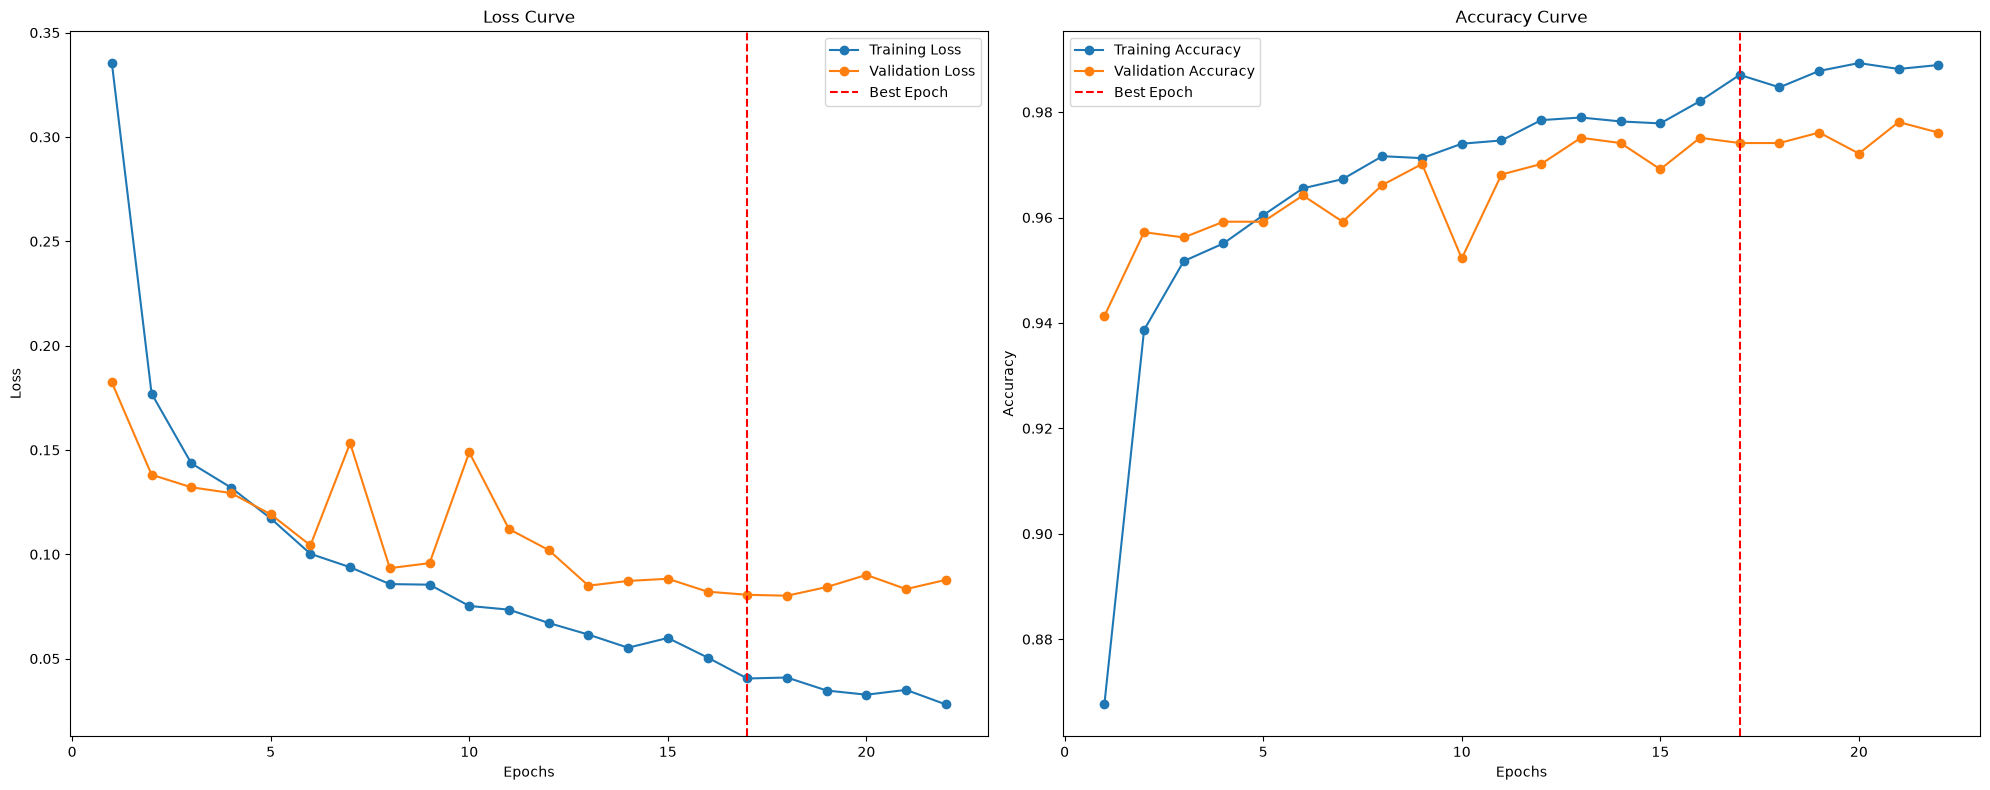


Training Report:
Total training time: 00:18:06
Total epochs run: 22
Best Training Loss: 0.0405 at epoch 17
Best Training Accuracy: 0.9871

Validation Report:
Best Validation Loss: 0.0806 at epoch 17
Best Validation Accuracy: 0.9741
Final Validation Loss: 0.0877
Final Validation Accuracy: 0.9761

Inference Report:
Total Inference Time (Validation only): 00:02:01


In [16]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [17]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97999
Recall:      0.97895
Precision:   0.97096
F1 Score:    0.97469
MCC:         0.97183
PR AUC:      0.99853
Kappa:       0.97177
Specificity: 0.99336


In [17]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98607
Recall:      0.98774
Precision:   0.97591
F1 Score:    0.98148
MCC:         0.97781
PR AUC:      0.99827
Kappa:       0.97765
Specificity: 0.99394


In [19]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
    
    # Check if the classification layer is a simple linear head, then replace it
    if hasattr(model, 'get_classifier'):
        in_features = model.get_classifier().in_features
        model.reset_classifier(0)  # Remove the existing head
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError(f"Model {model_name} does not support get_classifier method.")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("efficientnet_b4", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.2754, Validation Accuracy: 0.8925
Training Loss: 0.6046, Training Accuracy: 0.7287

Epoch 2/30
------------------------------


Validation Loss: 0.2196, Validation Accuracy: 0.9184
Training Loss: 0.2908, Training Accuracy: 0.8909

Epoch 3/30
------------------------------


Validation Loss: 0.1905, Validation Accuracy: 0.9403
Training Loss: 0.2257, Training Accuracy: 0.9168

Epoch 4/30
------------------------------


Validation Loss: 0.1386, Validation Accuracy: 0.9542
Training Loss: 0.2005, Training Accuracy: 0.9278

Epoch 5/30
------------------------------


Validation Loss: 0.1305, Validation Accuracy: 0.9572
Training Loss: 0.1698, Training Accuracy: 0.9415

Epoch 6/30
------------------------------


... (10 outputs left out)

Validation Loss: 0.0989, Validation Accuracy: 0.9652
Training Loss: 0.0881, Training Accuracy: 0.9689
Patience Counter: 2/5

Epoch 17/30
------------------------------


Validation Loss: 0.1047, Validation Accuracy: 0.9672
Training Loss: 0.0844, Training Accuracy: 0.9696
Patience Counter: 3/5

Epoch 18/30
------------------------------


Validation Loss: 0.1160, Validation Accuracy: 0.9622
Training Loss: 0.0804, Training Accuracy: 0.9701
Patience Counter: 4/5

Epoch 19/30
------------------------------


Validation Loss: 0.1046, Validation Accuracy: 0.9592
Training Loss: 0.0796, Training Accuracy: 0.9724
Patience Counter: 5/5
Early stopping triggered at epoch 19.


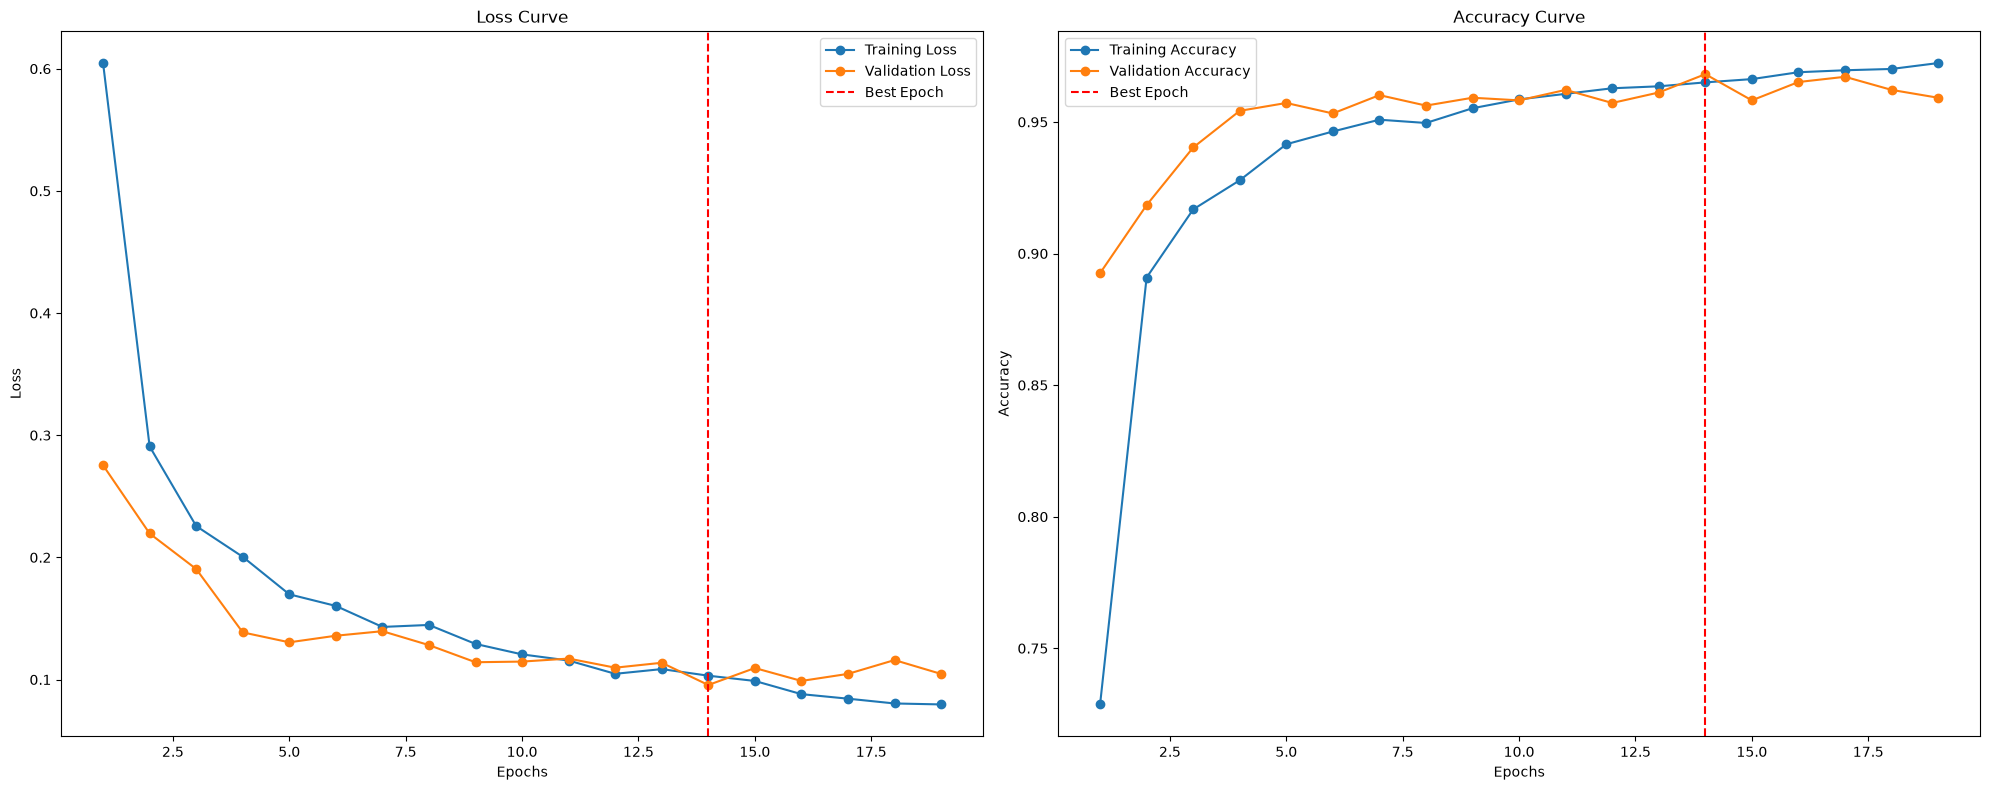


Training Report:
Total training time: 00:15:56
Total epochs run: 19
Best Training Loss: 0.1032 at epoch 14
Best Training Accuracy: 0.9650

Validation Report:
Best Validation Loss: 0.0955 at epoch 14
Best Validation Accuracy: 0.9682
Final Validation Loss: 0.1046
Final Validation Accuracy: 0.9592

Inference Report:
Total Inference Time (Validation only): 00:01:45


In [20]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [21]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.96816
Recall:      0.97107
Precision:   0.94836
F1 Score:    0.95808
MCC:         0.95014
PR AUC:      0.99730
Kappa:       0.94918
Specificity: 0.98615


In [23]:
import ssl, urllib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

def load_convnext_atto(num_classes, pretrained=False):
    model = timm.create_model('convnextv2_tiny', pretrained=pretrained, num_classes=num_classes)
    
    in_features = model.get_classifier().in_features
    model.reset_classifier(0)
    
    model.head.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.GELU(),
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
    )
    return model

model = load_convnext_atto(num_classes=len(label_mapping), pretrained=False).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 5. Scheduler fix: Force T_max to equal your actual total epochs.
# This prevents the learning rate from climbing back up and destroying your model's weights.
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)



Epoch 1/30
------------------------------


Validation Loss: 0.3305, Validation Accuracy: 0.8637
Training Loss: 0.4170, Training Accuracy: 0.8343

Epoch 2/30
------------------------------


Validation Loss: 0.2345, Validation Accuracy: 0.9144
Training Loss: 0.2714, Training Accuracy: 0.9017

Epoch 3/30
------------------------------


Validation Loss: 0.1724, Validation Accuracy: 0.9453
Training Loss: 0.2245, Training Accuracy: 0.9201

Epoch 4/30
------------------------------


Validation Loss: 0.2556, Validation Accuracy: 0.9085
Training Loss: 0.2009, Training Accuracy: 0.9270
Patience Counter: 1/5

Epoch 5/30
------------------------------


Validation Loss: 0.3350, Validation Accuracy: 0.8697
Training Loss: 0.1669, Training Accuracy: 0.9407
Patience Counter: 2/5

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.0854, Validation Accuracy: 0.9761
Training Loss: 0.0457, Training Accuracy: 0.9840
Patience Counter: 1/5

Epoch 28/30
------------------------------


Validation Loss: 0.0835, Validation Accuracy: 0.9741
Training Loss: 0.0457, Training Accuracy: 0.9828
Patience Counter: 2/5

Epoch 29/30
------------------------------


Validation Loss: 0.0849, Validation Accuracy: 0.9771
Training Loss: 0.0414, Training Accuracy: 0.9851
Patience Counter: 3/5

Epoch 30/30
------------------------------


Validation Loss: 0.0843, Validation Accuracy: 0.9731
Training Loss: 0.0449, Training Accuracy: 0.9833
Patience Counter: 4/5


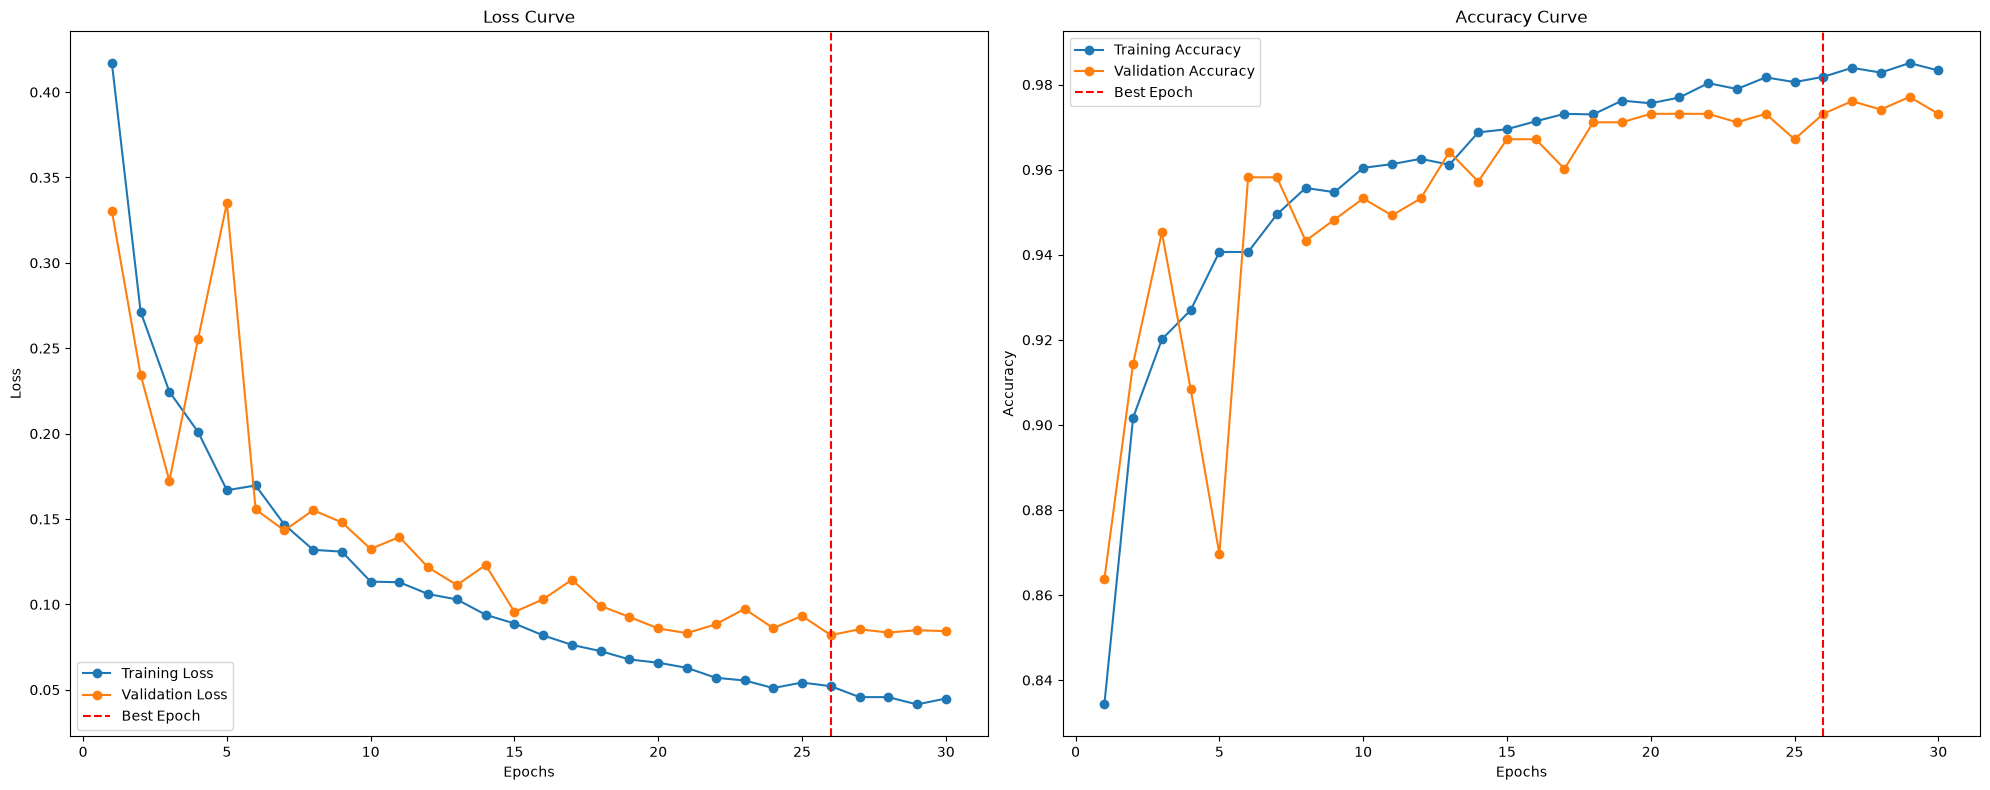


Training Report:
Total training time: 00:40:41
Total epochs run: 30
Best Training Loss: 0.0521 at epoch 26
Best Training Accuracy: 0.9818

Validation Report:
Best Validation Loss: 0.0820 at epoch 26
Best Validation Accuracy: 0.9731
Final Validation Loss: 0.0843
Final Validation Accuracy: 0.9731

Inference Report:
Total Inference Time (Validation only): 00:03:13


In [24]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [25]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98010
Recall:      0.97383
Precision:   0.97149
F1 Score:    0.97265
MCC:         0.96797
PR AUC:      0.99713
Kappa:       0.96796
Specificity: 0.99029


# Pneumonia


In [27]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("resnext101_32x4d", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.4499, Validation Accuracy: 0.8080
Training Loss: 0.4974, Training Accuracy: 0.7840

Epoch 2/30
------------------------------


Validation Loss: 0.1786, Validation Accuracy: 0.9383
Training Loss: 0.2408, Training Accuracy: 0.9077

Epoch 3/30
------------------------------


Validation Loss: 0.1611, Validation Accuracy: 0.9473
Training Loss: 0.1990, Training Accuracy: 0.9283

Epoch 4/30
------------------------------


Validation Loss: 0.1510, Validation Accuracy: 0.9483
Training Loss: 0.1821, Training Accuracy: 0.9357

Epoch 5/30
------------------------------


Validation Loss: 0.1656, Validation Accuracy: 0.9353
Training Loss: 0.1689, Training Accuracy: 0.9397
Patience Counter: 1/5

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.0947, Validation Accuracy: 0.9692
Training Loss: 0.0620, Training Accuracy: 0.9782
Patience Counter: 1/5

Epoch 28/30
------------------------------


Validation Loss: 0.0812, Validation Accuracy: 0.9741
Training Loss: 0.0609, Training Accuracy: 0.9803
Patience Counter: 2/5

Epoch 29/30
------------------------------


Validation Loss: 0.0795, Validation Accuracy: 0.9731
Training Loss: 0.0603, Training Accuracy: 0.9796
Patience Counter: 3/5

Epoch 30/30
------------------------------


Validation Loss: 0.0848, Validation Accuracy: 0.9731
Training Loss: 0.0562, Training Accuracy: 0.9802
Patience Counter: 4/5


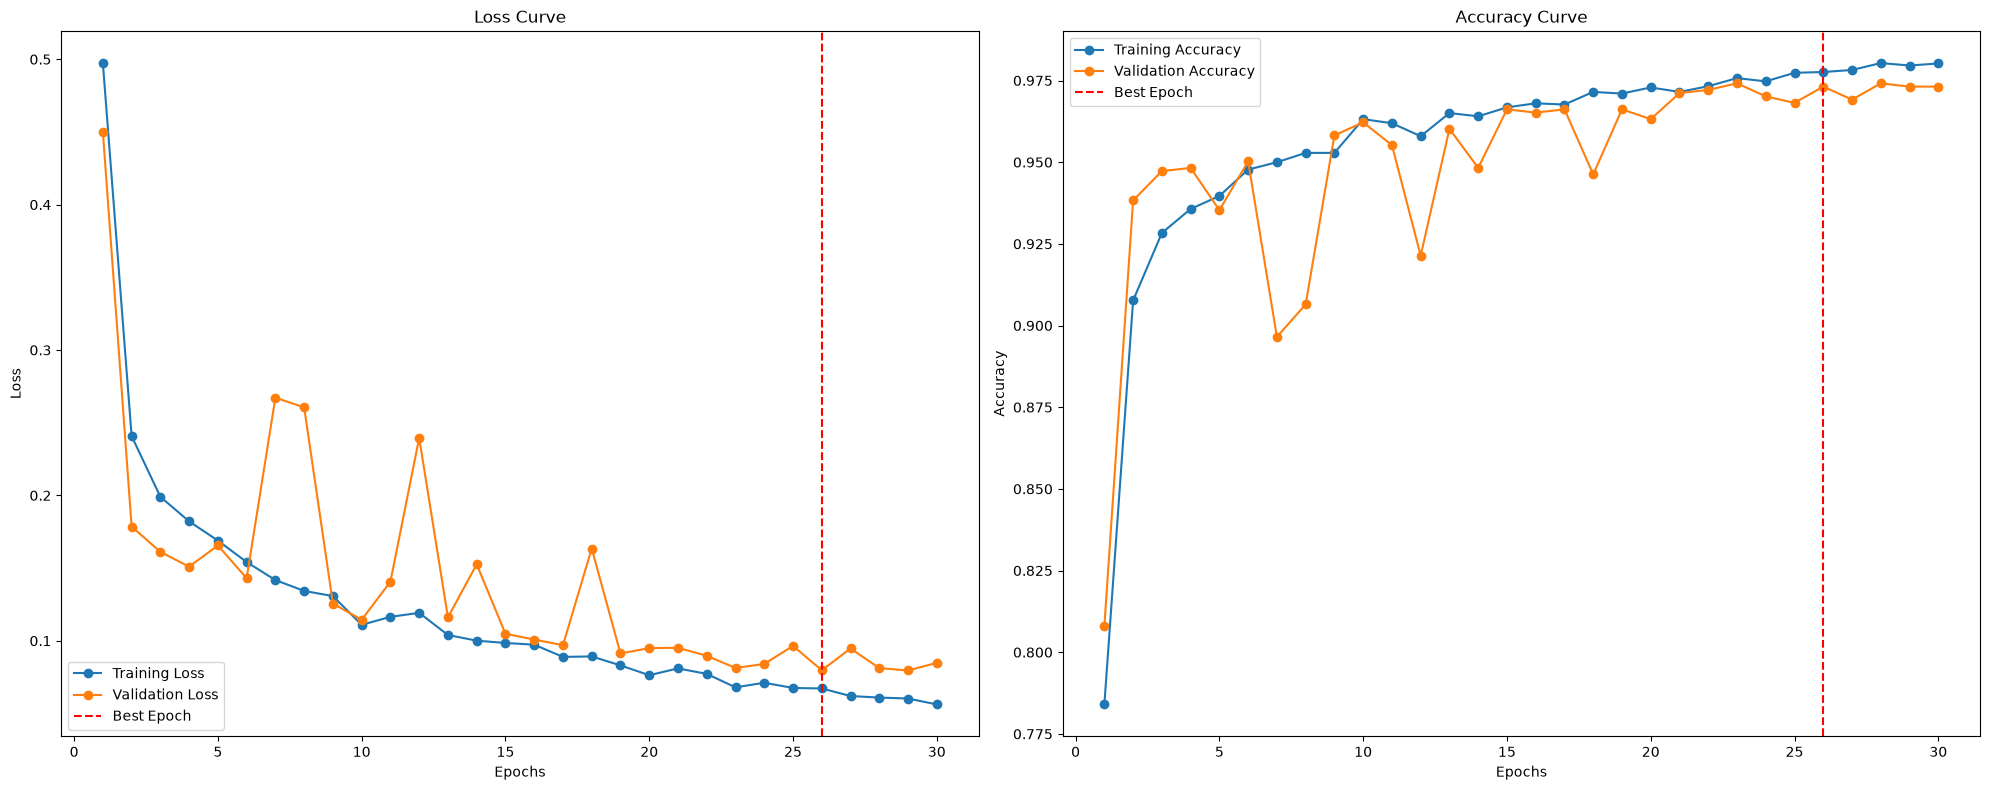


Training Report:
Total training time: 00:30:40
Total epochs run: 30
Best Training Loss: 0.0672 at epoch 26
Best Training Accuracy: 0.9776

Validation Report:
Best Validation Loss: 0.0797 at epoch 26
Best Validation Accuracy: 0.9731
Final Validation Loss: 0.0848
Final Validation Accuracy: 0.9731

Inference Report:
Total Inference Time (Validation only): 00:02:57


In [28]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [18]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97547
Recall:      0.97063
Precision:   0.97345
F1 Score:    0.97200
MCC:         0.96534
PR AUC:      0.99770
Kappa:       0.96532
Specificity: 0.99125


In [16]:
import ssl
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# 1. Instantiate MaxViT Tiny (TF 224 variant)
num_classes = len(label_mapping)

# Option A: Built-in timm drop_rate (recommended for MaxViT)
model = timm.create_model(
    'maxvit_tiny_tf_224', 
    pretrained=False, 
    num_classes=num_classes,
    drop_rate=0.4  # Applies dropout directly to the head
)

# Option B: Explicit manual head modification (if you prefer manual control)
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# 2. Loss & Optimizer
# Reduced label smoothing slightly to protect fine opacity classification confidence
criterion = nn.CrossEntropyLoss()

# MaxViT converges better with a slightly lower LR (3e-4 to 5e-4) and higher weight decay
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 3. Scheduler: Cosine Annealing
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.9727, Validation Accuracy: 0.6915
Training Loss: 0.3978, Training Accuracy: 0.8405

Epoch 2/30
------------------------------


Validation Loss: 0.2683, Validation Accuracy: 0.9085
Training Loss: 0.2176, Training Accuracy: 0.9204

Epoch 3/30
------------------------------


Validation Loss: 0.1355, Validation Accuracy: 0.9592
Training Loss: 0.1709, Training Accuracy: 0.9404

Epoch 4/30
------------------------------


Validation Loss: 0.1245, Validation Accuracy: 0.9632
Training Loss: 0.1520, Training Accuracy: 0.9464

Epoch 5/30
------------------------------


Validation Loss: 0.1728, Validation Accuracy: 0.9423
Training Loss: 0.1441, Training Accuracy: 0.9501
Patience Counter: 1/5

Epoch 6/30
------------------------------


... (7 outputs left out)

Validation Loss: 0.2117, Validation Accuracy: 0.9353
Training Loss: 0.0855, Training Accuracy: 0.9694
Patience Counter: 2/5

Epoch 14/30
------------------------------


Validation Loss: 0.1016, Validation Accuracy: 0.9692
Training Loss: 0.0754, Training Accuracy: 0.9734
Patience Counter: 3/5

Epoch 15/30
------------------------------


Validation Loss: 0.1102, Validation Accuracy: 0.9692
Training Loss: 0.0766, Training Accuracy: 0.9733
Patience Counter: 4/5

Epoch 16/30
------------------------------


Validation Loss: 0.1108, Validation Accuracy: 0.9632
Training Loss: 0.0680, Training Accuracy: 0.9772
Patience Counter: 5/5
Early stopping triggered at epoch 16.


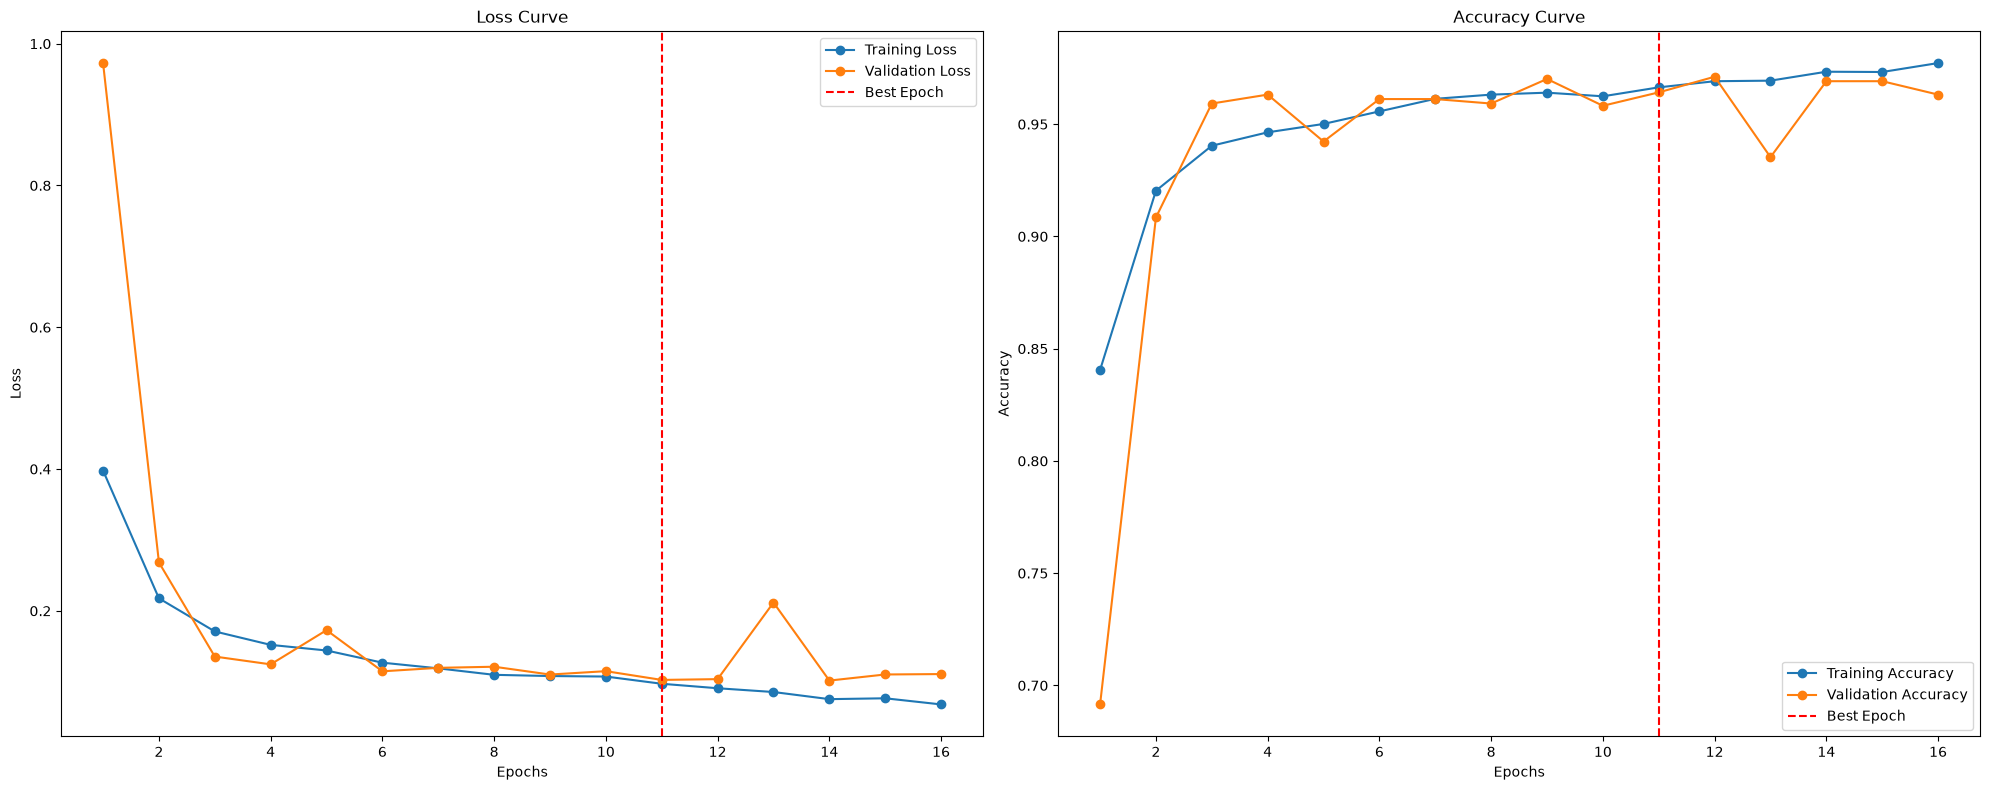


Training Report:
Total training time: 00:20:46
Total epochs run: 16
Best Training Loss: 0.0971 at epoch 11
Best Training Accuracy: 0.9664

Validation Report:
Best Validation Loss: 0.1026 at epoch 11
Best Validation Accuracy: 0.9642
Final Validation Loss: 0.1108
Final Validation Accuracy: 0.9632

Inference Report:
Total Inference Time (Validation only): 00:01:50


In [17]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [18]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98209
Recall:      0.98066
Precision:   0.97346
F1 Score:    0.97693
MCC:         0.97127
PR AUC:      0.99657
Kappa:       0.97122
Specificity: 0.99146


In [31]:
import ssl, urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Create LeViT (pick size: levit_128s / 128 / 192 / 256)
num_classes = len(label_mapping)
model = timm.create_model('levit_192', pretrained=False, num_classes=num_classes)
# LeViT-192 head has 384 input features
in_features = 384  

# Replace the head with dropout + linear
model.head = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, num_classes)
)

model = model.to(device)

# Loss & optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing
# T_max = total number of epochs (full cycle)
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)



Epoch 1/30
------------------------------


Validation Loss: 0.4170, Validation Accuracy: 0.8090
Training Loss: 0.6671, Training Accuracy: 0.7151

Epoch 2/30
------------------------------


Validation Loss: 0.2806, Validation Accuracy: 0.8886
Training Loss: 0.3802, Training Accuracy: 0.8461

Epoch 3/30
------------------------------


Validation Loss: 0.2552, Validation Accuracy: 0.9095
Training Loss: 0.3064, Training Accuracy: 0.8818

Epoch 4/30
------------------------------


Validation Loss: 0.3855, Validation Accuracy: 0.8328
Training Loss: 0.2729, Training Accuracy: 0.8956
Patience Counter: 1/5

Epoch 5/30
------------------------------


Validation Loss: 0.2250, Validation Accuracy: 0.9204
Training Loss: 0.2362, Training Accuracy: 0.9118

Epoch 6/30
------------------------------


... (21 outputs left out)

Validation Loss: 0.1052, Validation Accuracy: 0.9652
Training Loss: 0.0994, Training Accuracy: 0.9647
Patience Counter: 4/5

Epoch 28/30
------------------------------


Validation Loss: 0.1014, Validation Accuracy: 0.9632
Training Loss: 0.0980, Training Accuracy: 0.9655

Epoch 29/30
------------------------------


Validation Loss: 0.1042, Validation Accuracy: 0.9672
Training Loss: 0.1001, Training Accuracy: 0.9650
Patience Counter: 1/5

Epoch 30/30
------------------------------


Validation Loss: 0.1055, Validation Accuracy: 0.9592
Training Loss: 0.0935, Training Accuracy: 0.9678
Patience Counter: 2/5


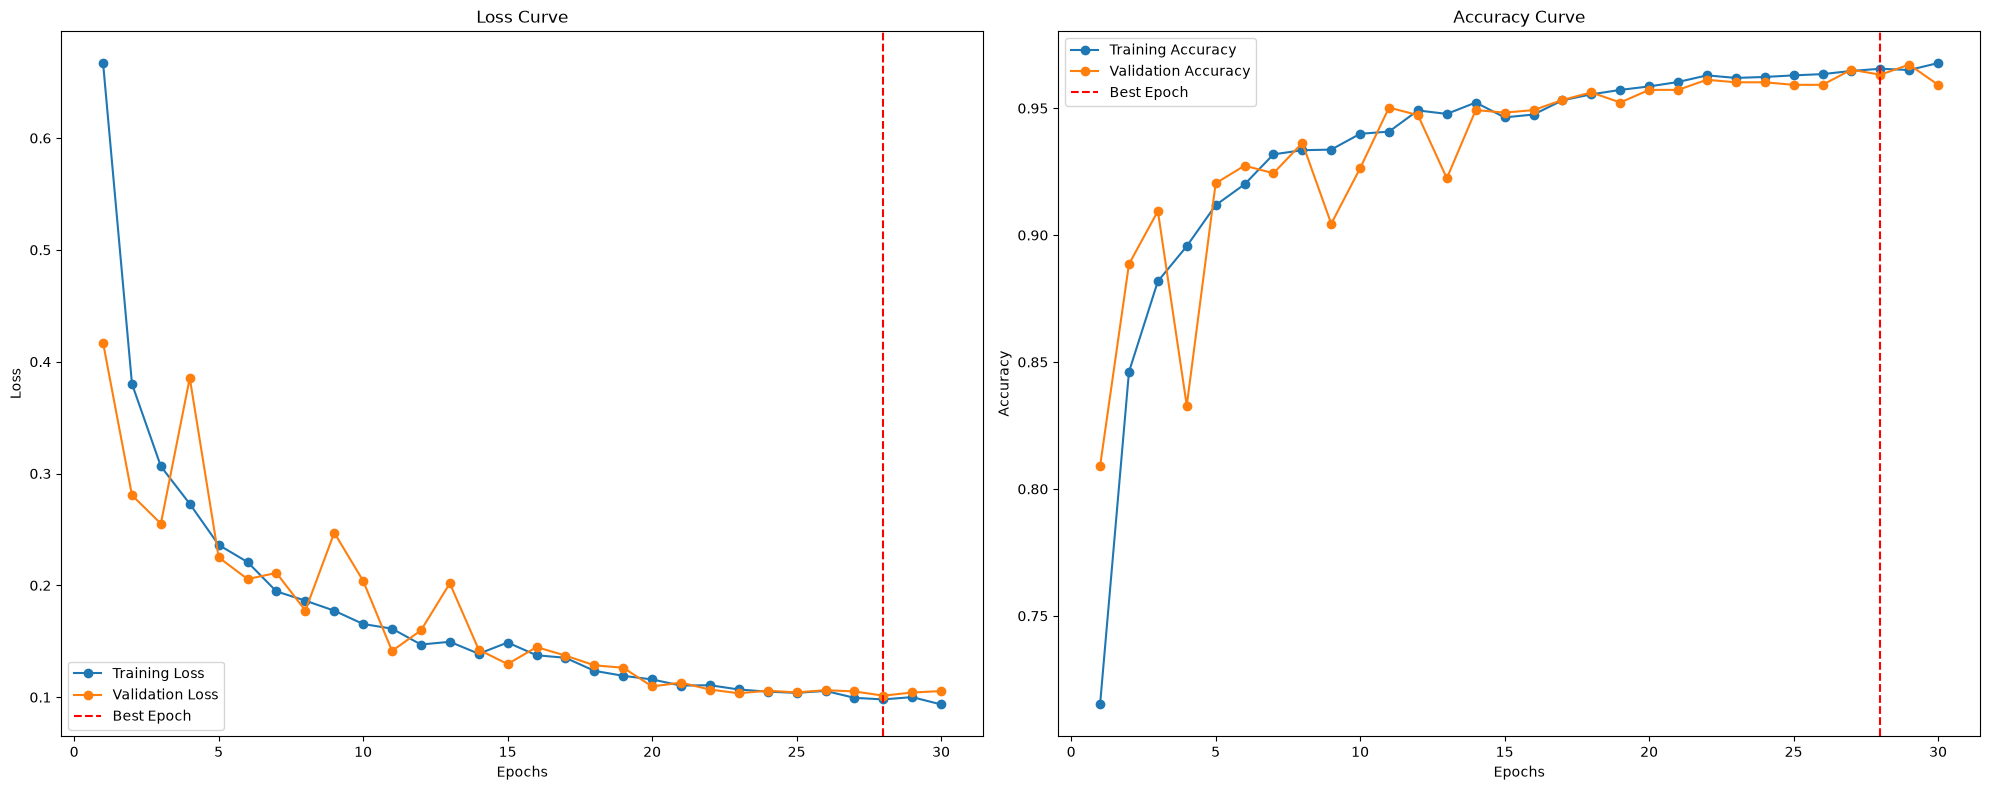


Training Report:
Total training time: 00:12:32
Total epochs run: 30
Best Training Loss: 0.0980 at epoch 28
Best Training Accuracy: 0.9655

Validation Report:
Best Validation Loss: 0.1014 at epoch 28
Best Validation Accuracy: 0.9632
Final Validation Loss: 0.1055
Final Validation Accuracy: 0.9592

Inference Report:
Total Inference Time (Validation only): 00:02:26


In [32]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [33]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97313
Recall:      0.96442
Precision:   0.95988
F1 Score:    0.96210
MCC:         0.95681
PR AUC:      0.99600
Kappa:       0.95679
Specificity: 0.98718


In [35]:
import ssl
import urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Target model identification
model_name = 'swinv2_cr_tiny_224'
num_classes = len(label_mapping)

# Create SwinV2 model (Set pretrained=True for massive accuracy gains on small leaf datasets)
model = timm.create_model(model_name, pretrained=False, num_classes=num_classes)

# Modify the head properly according to SwinV2's internal architecture structure
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
elif hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# Loss & optimizer (Kept the same, AdamW is great for Swin architectures)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing 
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.5246, Validation Accuracy: 0.7721
Training Loss: 0.8158, Training Accuracy: 0.6458

Epoch 2/30
------------------------------


Validation Loss: 0.3020, Validation Accuracy: 0.8846
Training Loss: 0.3961, Training Accuracy: 0.8446

Epoch 3/30
------------------------------


Validation Loss: 0.2782, Validation Accuracy: 0.8965
Training Loss: 0.2924, Training Accuracy: 0.8865

Epoch 4/30
------------------------------


Validation Loss: 0.2325, Validation Accuracy: 0.9144
Training Loss: 0.2422, Training Accuracy: 0.9094

Epoch 5/30
------------------------------


Validation Loss: 0.2129, Validation Accuracy: 0.9154
Training Loss: 0.2299, Training Accuracy: 0.9144

Epoch 6/30
------------------------------


... (15 outputs left out)

Validation Loss: 0.1048, Validation Accuracy: 0.9662
Training Loss: 0.0885, Training Accuracy: 0.9685
Patience Counter: 2/5

Epoch 22/30
------------------------------


Validation Loss: 0.0941, Validation Accuracy: 0.9711
Training Loss: 0.0877, Training Accuracy: 0.9684
Patience Counter: 3/5

Epoch 23/30
------------------------------


Validation Loss: 0.0906, Validation Accuracy: 0.9721
Training Loss: 0.0839, Training Accuracy: 0.9698
Patience Counter: 4/5

Epoch 24/30
------------------------------


Validation Loss: 0.0934, Validation Accuracy: 0.9692
Training Loss: 0.0794, Training Accuracy: 0.9730
Patience Counter: 5/5
Early stopping triggered at epoch 24.


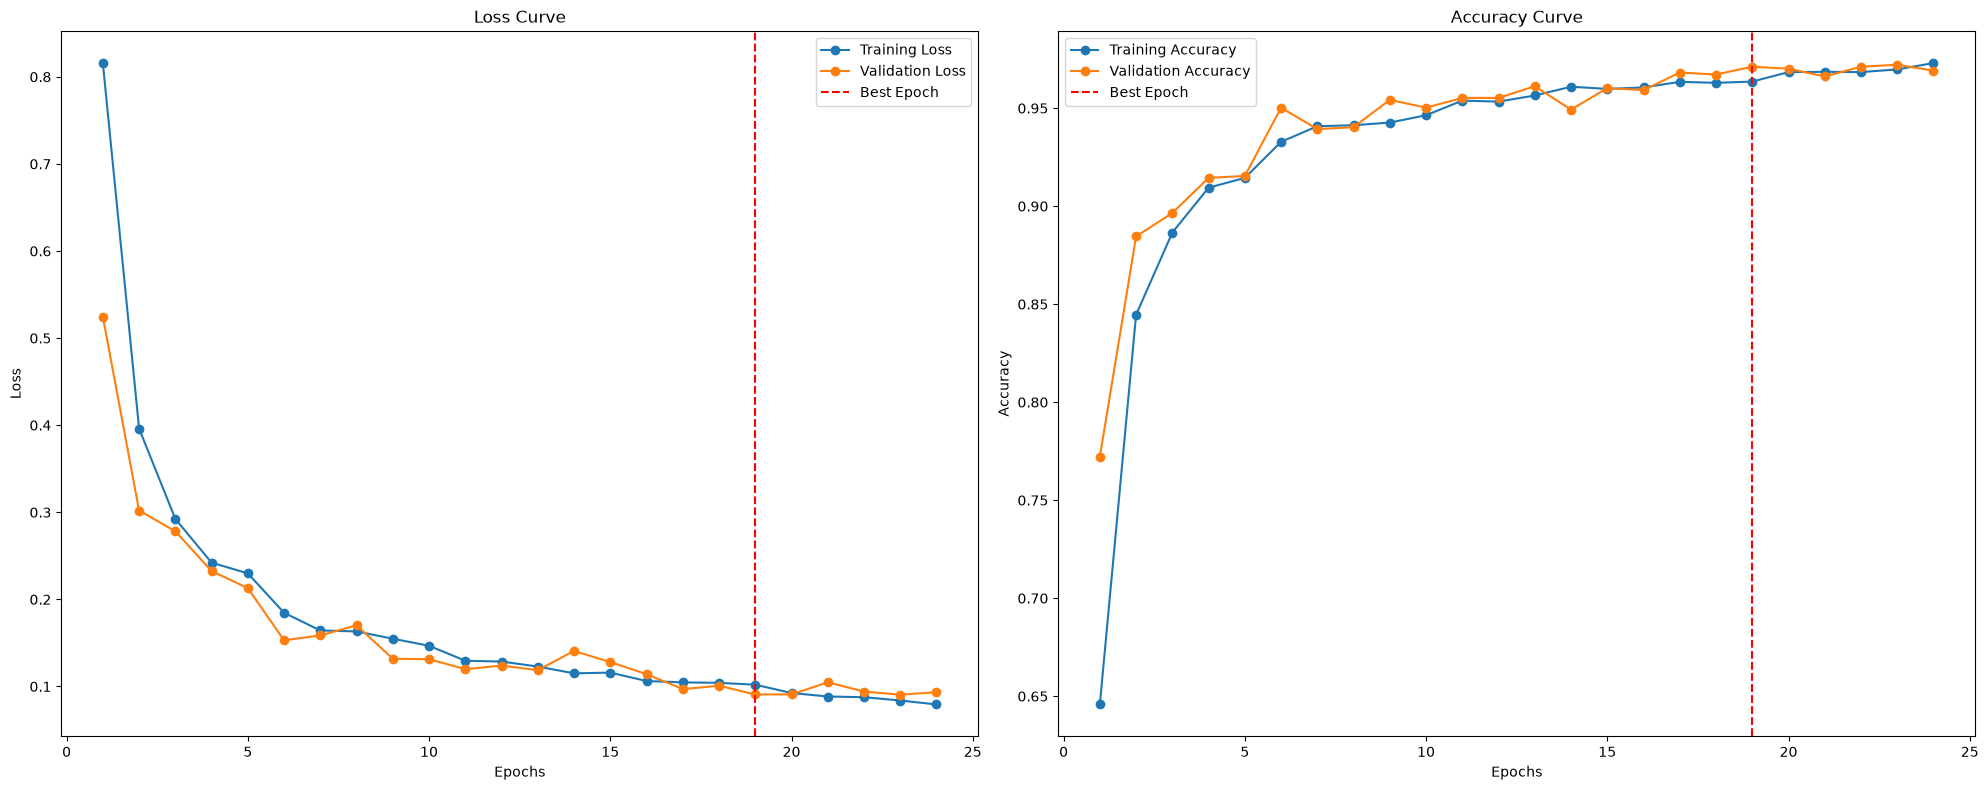


Training Report:
Total training time: 00:24:11
Total epochs run: 24
Best Training Loss: 0.1020 at epoch 19
Best Training Accuracy: 0.9635

Validation Report:
Best Validation Loss: 0.0908 at epoch 19
Best Validation Accuracy: 0.9711
Final Validation Loss: 0.0934
Final Validation Accuracy: 0.9692

Inference Report:
Total Inference Time (Validation only): 00:02:24


In [36]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [37]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97413
Recall:      0.97049
Precision:   0.96026
F1 Score:    0.96507
MCC:         0.95866
PR AUC:      0.99527
Kappa:       0.95848
Specificity: 0.98795
